# **Лабораторная работа 2. Односвязный список. Стек. Очередь. Амортизационный анализ. Динамический массив. Очередь на двух стеках. Куча.**

**Предварительная подготовка.**

**СКОПИРУЙТЕ ФАЙЛ**

ОБЯЗАТЕЛЬНО ЗДЕСЬ НАПИШИТЕ ФАМИЛИЮ.

Мамаев

Сдаете в LMS вы ipynb версию скачанную (не colab). При необходимости, вы можете сдать дополнительно файл (оформленный в любом читаемом виде).

Пожалуйста, не надо использовать ИИ для ответов на вопросы и написания кода. Отвечать на вопросы лучше прям здесь, под заданиями, где были написаны вопросы.

**Во всех задачах демонстрируйте вывод на каких-то тестовых данных.**

**Цель работы**

Реализовать базовые линейные структуры данных (односвязный список, стек, очередь, динамический массив, очередь на двух стеках) и двоичную кучу, экспериментально подтвердить их асимптотику и на практике попробовать применить амортизационный анализ.

**Баллы**

| Задание | Тема | Баллы |
|---|---|---|
| 1 | Односвязный список | 2 |
| 2 | Стек и очередь | 2 |
| 3 | Динамический массив и амортизационный анализ | 2 |
| 4 | Очередь на двух стеках | 2 |
| 5 | Двоичная куча | 2 |

# 0. Как измерять амортизированную стоимость операций

В прошлой лабораторной мы измеряли время работы **одного вызова** алгоритма. Со структурами данных все чуть иначе: отдельная операция может быть то дешёвой, то очень дорогой. Поэтому нас будут интересовать три величины:

1. **Фактическая стоимость $c_i$** каждой отдельной операции.
2. **Суммарная стоимость** $\sum_{j=1}^{i} c_j$ первых $i$ операций.
3. **Средняя (амортизированная) стоимость** $\frac{1}{i}\sum_{j=1}^{i} c_j$.

Как и раньше, время — величина довольно шумная и измерить замером времени будет проблемно, поэтому основным инструментом будет **подсчёт элементарных операций**.

Разберём всё на примере из лекции — **двоичного счётчика**. Операция `increment` прибавляет единицу; её стоимость — число изменённых битов.

In [1]:
import random
import sys
import time
import tracemalloc

import matplotlib.pyplot as plt
import numpy as np


def increment(bits):
    """bits[0] — младший бит. Возвращает число изменённых битов (стоимость операции)."""
    cost = 0
    i = 0
    while i < len(bits) and bits[i] == 1:
        bits[i] = 0
        cost += 1
        i += 1
    if i < len(bits):
        bits[i] = 1
        cost += 1
    return cost

Выполним $n$ операций и запишем стоимость каждой из них, а также накопленную сумму.

In [2]:
n = 1024
bits = [0] * 16

costs = []  # фактическая стоимость каждой операции
cumulative = []  # суммарная стоимость первых i операций
total = 0
for i in range(n):
    c = increment(bits)
    costs.append(c)
    total += c
    cumulative.append(total)

ops = np.arange(1, n + 1)
print("Максимальная стоимость одной операции:", max(costs))
print("Суммарная стоимость:", total, " граница 2n =", 2 * n)

Максимальная стоимость одной операции: 11
Суммарная стоимость: 2047  граница 2n = 2048


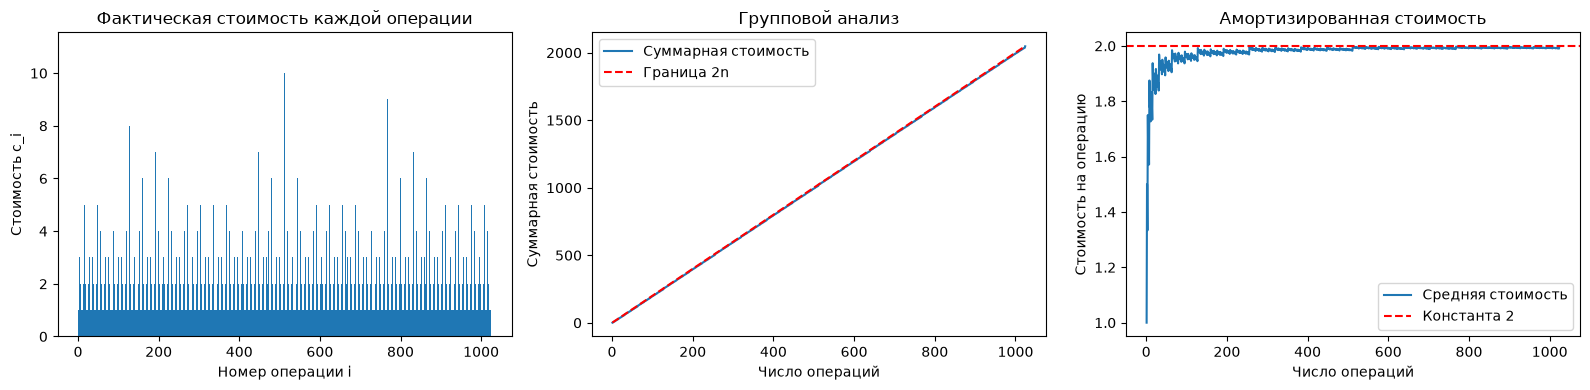

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].bar(ops, costs, width=1.0)
axes[0].set_xlabel("Номер операции i")
axes[0].set_ylabel("Стоимость c_i")
axes[0].set_title("Фактическая стоимость каждой операции")

axes[1].plot(ops, cumulative, label="Суммарная стоимость")
axes[1].plot(ops, 2 * ops, "r--", label="Граница 2n")
axes[1].set_xlabel("Число операций")
axes[1].set_ylabel("Суммарная стоимость")
axes[1].set_title("Групповой анализ")
axes[1].legend()

axes[2].plot(ops, np.array(cumulative) / ops, label="Средняя стоимость")
axes[2].axhline(2, color="r", linestyle="--", label="Константа 2")
axes[2].set_xlabel("Число операций")
axes[2].set_ylabel("Стоимость на операцию")
axes[2].set_title("Амортизированная стоимость")
axes[2].legend()

plt.tight_layout()
plt.show()

Отдельные операции стоят до $\log_2 n + 1$, но суммарная стоимость лежит под прямой $2n$, а средняя стремится к константе $2$. Именно это и означает «амортизированное $O(1)$».

### Проверка через метод потенциалов

Можно проверить и метод потенциалов: при $\Phi$ = число единиц в счётчике амортизированная стоимость $\hat{c}_i = c_i + \Phi_i - \Phi_{i-1}$ должна быть не больше $2$ **для каждой** операции.

In [4]:
bits = [0] * 16
phi_prev = 0
amortized = []
for i in range(n):
    c = increment(bits)
    phi = sum(bits)
    amortized.append(c + phi - phi_prev)
    phi_prev = phi

print("max амортизированной стоимости:", max(amortized))
assert max(amortized) <= 2

max амортизированной стоимости: 2


## Как измерять время отдельной операции

Время одной быстрой операции — сотни наносекунд, и шум сравним с самим измерением. Поэтому:
* время **одной операции** измеряем через `perf_counter_ns()` и смотрим на форму графика (выбросы — ожидаемы);
* время **серии из N операций** измеряем целиком и повторяем замер несколько раз, отбрасывая минимум и максимум.

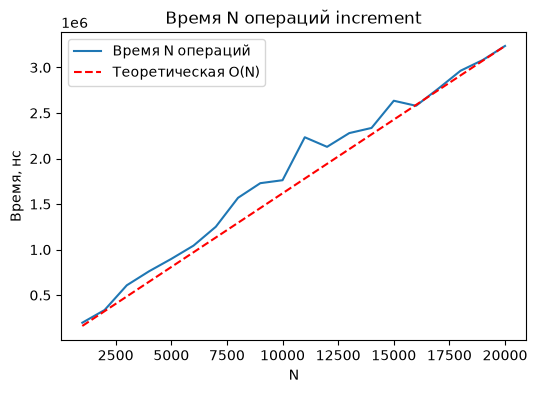

In [5]:
def measure_series(func, N, repeats=7):
    """Среднее время (в нс) выполнения func(N), без минимального и максимального замеров."""
    times = []
    for _ in range(repeats):
        start = time.perf_counter_ns()
        func(N)
        end = time.perf_counter_ns()
        times.append(end - start)
    times.sort()
    times = times[1:-1]
    return sum(times) / len(times)


# пример: N инкрементов двоичного счётчика
def run_counter(N):
    bits = [0] * 32
    for _ in range(N):
        increment(bits)


N_GRID = list(range(1000, 20001, 1000))
counter_times = [measure_series(run_counter, N) for N in N_GRID]

plt.figure(figsize=(6, 4))
plt.plot(N_GRID, counter_times, label="Время N операций")
scale = counter_times[-1] / N_GRID[-1]
plt.plot(N_GRID, [scale * N for N in N_GRID], "r--", label="Теоретическая O(N)")
plt.xlabel("N")
plt.ylabel("Время, нс")
plt.title("Время N операций increment")
plt.legend()
plt.show()

## Как измерять память

Для оценки памяти будем использовать модуль `tracemalloc`: он показывает, сколько байт было выделено во время работы кода. `sys.getsizeof(obj)` возвращает размер **только самого объекта**, без объектов, на которые он ссылается.

In [6]:
def measure_memory(builder, N):
    """Пиковый объём памяти (в байтах), выделенной при вызове builder(N)."""
    tracemalloc.start()
    obj = builder(N)  # объект должен «жить», пока мы измеряем
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak


print("list из 10000 чисел:", measure_memory(lambda N: list(range(N)), 10_000), "байт")
print("getsizeof того же списка:", sys.getsizeof(list(range(10_000))), "байт")

list из 10000 чисел: 389175 байт
getsizeof того же списка: 80056 байт


# Задание 1 (2 балла). Односвязный список

**Односвязный список** — последовательность узлов, каждый из которых хранит значение и ссылку на следующий узел. Список хранит ссылку на первый узел `head` и (опционально) на последний `tail`.

```
head                               tail
 ↓                                  ↓
[1 | •]──→[2 | •]──→[3 | •]──→[4 | None]
```

В отличие от массива, элементы лежат в памяти не подряд, поэтому доступ по индексу — $O(n)$, зато вставка/удаление в начале — $O(1)$.

### Предварительная подготовка

1. Реализовать класс `Node` и класс `SinglyLinkedList` **с указателем на хвост** со следующим интерфейсом:

| Метод | Что делает |
|---|---|
| `push_front(x)` | добавить в начало |
| `push_back(x)` | добавить в конец |
| `pop_front()` | удалить и вернуть первый элемент (`IndexError`, если пуст) |
| `pop_back()` | удалить и вернуть последний элемент (`IndexError`, если пуст) |
| `get(i)` | значение по индексу (`IndexError`, если индекс вне диапазона) |
| `find(x)` | `True`, если значение есть в списке |
| `remove(x)` | удалить первое вхождение `x`, вернуть `True`/`False` |
| `reverse()` | развернуть список **на месте**, без создания новых узлов |
| `__len__`, `__iter__`, `__str__` | длина за $O(1)$, обход, строка вида `1 -> 2 -> 3` |

2. Реализовать класс `SinglyLinkedListNoTail` — тот же список, но **без** указателя `tail` (достаточно методов `push_front`, `push_back`, `pop_front`, `__len__`, `__iter__`).
3. Для подсчёта операций добавьте в оба класса счётчик `self.ops`: увеличивайте его на 1 при каждом переходе по ссылке `node = node.next` и при каждом создании узла.
4. Для каждого метода указать асимптотику и **обосновать** её. Объяснить, почему `pop_back` работает за $O(n)$ даже при наличии `tail`.

In [7]:
class Node:
    def __init__(self, value, next=None):
        self.value = value
        self.next = next

class SinglyLinkedList:
    def __init__(self):
        self.head = None
        self.tail = None
        self.size = 0
        self.ops = 0

    def push_front(self, x):
        node = Node(x, self.head)
        self.ops += 1
        self.head = node
        if self.tail is None:
            self.tail = node
        self.size += 1

    def push_back(self, x):
        node = Node(x, None)
        self.ops += 1
        if self.tail is None:
            self.head = self.tail = node
        else:
            self.tail.next = node
            self.tail = node
        self.size += 1

    def pop_front(self):
        if self.head is None:
            raise IndexError("pop from empty list")
        node = self.head
        self.head = node.next
        if self.head is None:
            self.tail = None
        self.size -= 1
        return node.value

    def pop_back(self):
        if self.head is None:
            raise IndexError("pop from empty list")
        if self.head is self.tail:
            value = self.head.value
            self.head = self.tail = None
        else:
            prev = self.head
            while prev.next is not self.tail:
                nxt = prev.next
                assert nxt is not None
                prev = nxt
                self.ops += 1
            assert self.tail is not None
            value = self.tail.value
            prev.next = None
            self.tail = prev
        self.size -= 1
        return value

    def get(self, i):
        if not 0 <= i < self.size:
            raise IndexError("index out of range")
        node = self.head
        for _ in range(i):
            assert node is not None
            node = node.next
            self.ops += 1
        assert node is not None
        return node.value

    def find(self, x):
        node = self.head
        while node is not None:
            if node.value == x:
                return True
            node = node.next
            self.ops += 1
        return False

    def remove(self, x):
        prev, node = None, self.head
        while node is not None:
            if node.value == x:
                if prev is None:
                    self.head = node.next
                else:
                    prev.next = node.next
                if node is self.tail:
                    self.tail = prev
                self.size -= 1
                return True
            prev, node = node, node.next
            self.ops += 1
        return False

    def reverse(self):
        prev, node = None, self.head
        self.tail = self.head
        while node is not None:
            nxt = node.next
            node.next = prev
            prev, node = node, nxt
            self.ops += 1
        self.head = prev

    def __len__(self):
        return self.size

    def __iter__(self):
        node = self.head
        while node is not None:
            yield node.value
            node = node.next

    def __str__(self):
        return " -> ".join(str(v) for v in self)

class SinglyLinkedListNoTail:
    def __init__(self):
        self.head = None
        self.size = 0
        self.ops = 0

    def push_front(self, x):
        self.head = Node(x, self.head)
        self.ops += 1
        self.size += 1

    def push_back(self, x):
        node = Node(x)
        self.ops += 1
        if self.head is None:
            self.head = node
        else:
            cur = self.head
            while cur.next is not None:  # приходится идти до конца
                cur = cur.next
                self.ops += 1
            cur.next = node
        self.size += 1

    def pop_front(self):
        if self.head is None:
            raise IndexError("pop from empty list")
        node = self.head
        self.head = node.next
        self.size -= 1
        return node.value

    def __len__(self):
        return self.size

    def __iter__(self):
        node = self.head
        while node is not None:
            yield node.value
            node = node.next

**Асимптотика методов `SinglyLinkedList`**

| Метод | Время | Обоснование |
|---|---|---|
| `push_front` | $O(1)$ | создаём узел и переставляем `head` — фиксированное число действий |
| `push_back` | $O(1)$ | благодаря `tail` не нужно идти по списку: `tail.next = node; tail = node` |
| `pop_front` | $O(1)$ | сдвигаем `head` на следующий узел |
| `pop_back` | $O(n)$ | см. ниже |
| `get(i)` | $O(i) = O(n)$ | чтобы попасть в узел `i`, нужно пройти `i` ссылок от `head` |
| `find(x)` | $O(n)$ | линейный просмотр; в худшем случае (`x` нет или он последний) проходим весь список |
| `remove(x)` | $O(n)$ | поиск за $O(n)$, само «вырезание» узла при известном предшественнике — $O(1)$ |
| `reverse()` | $O(n)$ | один проход, на каждом узле перенаправляем `next` назад; $O(1)$ дополнительной памяти |
| `__len__` | $O(1)$ | хранится счётчик `size` |
| `__iter__`, `__str__` | $O(n)$ | полный обход (`__iter__` — $O(1)$ на шаг) |

**Почему `pop_back` — $O(n)$ даже с `tail`.** `tail` даёт доступ к последнему узлу, но чтобы удалить его, нужно обнулить `next` у **предпоследнего** узла и сдвинуть `tail` на него. В односвязном списке ссылок назад нет, поэтому предпоследний узел можно найти только обходом от `head` за $n-2$ переходов. (Для $O(1)$ нужен двусвязный список.)

В `SinglyLinkedListNoTail`: `push_front`, `pop_front`, `__len__` — $O(1)$; `push_back` — $O(n)$, т.к. приходится дойти до последнего узла; суммарно $N$ вызовов `push_back` дают $0+1+\dots+(N-1)=\frac{N(N-1)}{2}$ переходов, то есть $\Theta(N^2)$.

Запустите проверку. Все `assert` должны пройти.

In [8]:
ll = SinglyLinkedList()
assert len(ll) == 0 and str(ll) == ""
for x in [2, 3, 4]:
    ll.push_back(x)
ll.push_front(1)
assert str(ll) == "1 -> 2 -> 3 -> 4" and len(ll) == 4
assert list(ll) == [1, 2, 3, 4]
assert ll.get(0) == 1 and ll.get(3) == 4
assert ll.find(3) and not ll.find(10)
assert ll.remove(3) and not ll.remove(10)
assert list(ll) == [1, 2, 4]
ll.reverse()
assert list(ll) == [4, 2, 1]
ll.push_back(7)  # tail должен быть корректным после reverse
assert list(ll) == [4, 2, 1, 7]
assert ll.pop_back() == 7 and ll.pop_front() == 4
assert list(ll) == [2, 1] and len(ll) == 2
ll.pop_back()
ll.pop_back()
assert len(ll) == 0 and list(ll) == []
ll.push_back(5)  # после опустошения head и tail должны обнулиться
assert list(ll) == [5]
for method in (ll.pop_front, ll.pop_back):
    ll2 = SinglyLinkedList()
    try:
        getattr(ll2, method.__name__)()
        assert False, "ожидалось IndexError"
    except IndexError:
        pass

nt = SinglyLinkedListNoTail()
for x in range(5):
    nt.push_back(x)
assert list(nt) == [0, 1, 2, 3, 4] and nt.pop_front() == 0 and len(nt) == 4
print("Все проверки пройдены!")

Все проверки пройдены!


### Провести эксперименты

5. Взять размеры от 500 до 5000 с шагом 500.
6. Для каждого размера N построить структуру из N элементов следующими способами:
  * `SinglyLinkedList.push_front` (N раз);
  * `SinglyLinkedList.push_back` (N раз);
  * `SinglyLinkedListNoTail.push_back` (N раз);
  * `list.append` (N раз);
  * `list.insert(0, x)` (N раз).
7. Для каждого способа и каждого N:
  * подсчитать среднее время выполнения (не менее 10 повторных замеров);
  * подсчитать количество операций (для ваших классов — счётчик `ops`).
8. Сравнить доступ к элементу в середине: `SinglyLinkedList.get(N // 2)` и `list[N // 2]` (время).
9. С помощью `tracemalloc` измерить память, занимаемую `SinglyLinkedList` и `list` из N целых чисел.

In [9]:
SIZES1 = list(range(500, 5001, 500))

def theory(xs, ys, power):
    """Кривая c * x ** power, подогнанная под последнюю точку ys."""
    xs = np.asarray(xs, dtype=float)
    return ys[-1] / xs[-1] ** power * xs ** power

def build_ll_front(N):
    ll = SinglyLinkedList()
    for i in range(N):
        ll.push_front(i)
    return ll

def build_ll_back(N):
    ll = SinglyLinkedList()
    for i in range(N):
        ll.push_back(i)
    return ll

def build_nt_back(N):
    ll = SinglyLinkedListNoTail()
    for i in range(N):
        ll.push_back(i)
    return ll

def build_list_append(N):
    lst = [i for i in range(N)]  # иначе ruff ругается
    return lst

def build_list_insert0(N):
    lst = []
    for i in range(N):
        lst.insert(0, i)
    return lst

METHODS1 = {
    "SinglyLinkedList.push_front": build_ll_front,
    "SinglyLinkedList.push_back": build_ll_back,
    "SinglyLinkedListNoTail.push_back": build_nt_back,
    "list.append": build_list_append,
    "list.insert(0, x)": build_list_insert0,
}

time1, ops1 = {}, {}
for name, builder in METHODS1.items():
    time1[name] = [
        measure_series(builder, N, repeats=12) for N in SIZES1
    ]  # 10 замеров после отбрасывания min/max
    ops1[name] = [getattr(builder(N), "ops", None) for N in SIZES1]

for name in METHODS1:
    print(
        f"{name:34s} N=5000: время {time1[name][-1] / 1e6:9.3f} мс, ops = {ops1[name][-1]}"
    )
print("N(N-1)/2 при N=5000:", 5000 * 4999 // 2)

# доступ к середине
def time_mid(N):
    ll, lst, mid = build_ll_back(N), list(range(N)), N // 2

    def f_ll(_):
        for _ in range(100):
            ll.get(mid)

    def f_list(_):
        for _ in range(100):
            lst[mid]

    return measure_series(f_ll, N, 10) / 100, measure_series(f_list, N, 10) / 100

mid_res = [time_mid(N) for N in SIZES1]
mid_ll_t = [r[0] for r in mid_res]
mid_list_t = [r[1] for r in mid_res]
print(
    f"доступ к середине при N=5000: ll.get = {mid_ll_t[-1]:.0f} нс, list[i] = {mid_list_t[-1]:.0f} нс"
)

# память
mem_ll = [measure_memory(build_ll_back, N) for N in SIZES1]
mem_list = [measure_memory(lambda N: list(range(N)), N) for N in SIZES1]
mem_ratio = mem_ll[-1] / mem_list[-1]
print(
    f"память при N=5000: SinglyLinkedList = {mem_ll[-1]} Б, list = {mem_list[-1]} Б, отношение = {mem_ratio:.2f}"
)
print(
    "размер одного узла (sys.getsizeof):",
    sys.getsizeof(Node(0)),
    "Б; размер int:",
    sys.getsizeof(10 ** 4),
    "Б",
)

SinglyLinkedList.push_front        N=5000: время     1.553 мс, ops = 5000
SinglyLinkedList.push_back         N=5000: время     1.181 мс, ops = 5000
SinglyLinkedListNoTail.push_back   N=5000: время   400.847 мс, ops = 12497501
list.append                        N=5000: время     0.120 мс, ops = None
list.insert(0, x)                  N=5000: время     2.485 мс, ops = None
N(N-1)/2 при N=5000: 12497500
доступ к середине при N=5000: ll.get = 116210 нс, list[i] = 15 нс
память при N=5000: SinglyLinkedList = 588776 Б, list = 188664 Б, отношение = 3.12
размер одного узла (sys.getsizeof): 48 Б; размер int: 28 Б


### Построить графики

10. На одном графике — время построения структуры всеми пятью способами. Теоретические кривые $O(N)$ и $O(N^2)$ — пунктиром.
11. На одном графике — количество операций для `push_front`, `push_back` с хвостом и без хвоста.
12. На одном графике — время доступа к середине для списка и `list`.
13. На одном графике — память связного списка и `list`. Подпишите, во сколько раз отличаются значения при N = 5000.

**Требования к графикам:**

Сделайте
* Подписи осей
* Заголовок
* Легенду с пояснением всех линий
* Теоретические кривые — пунктирной линией

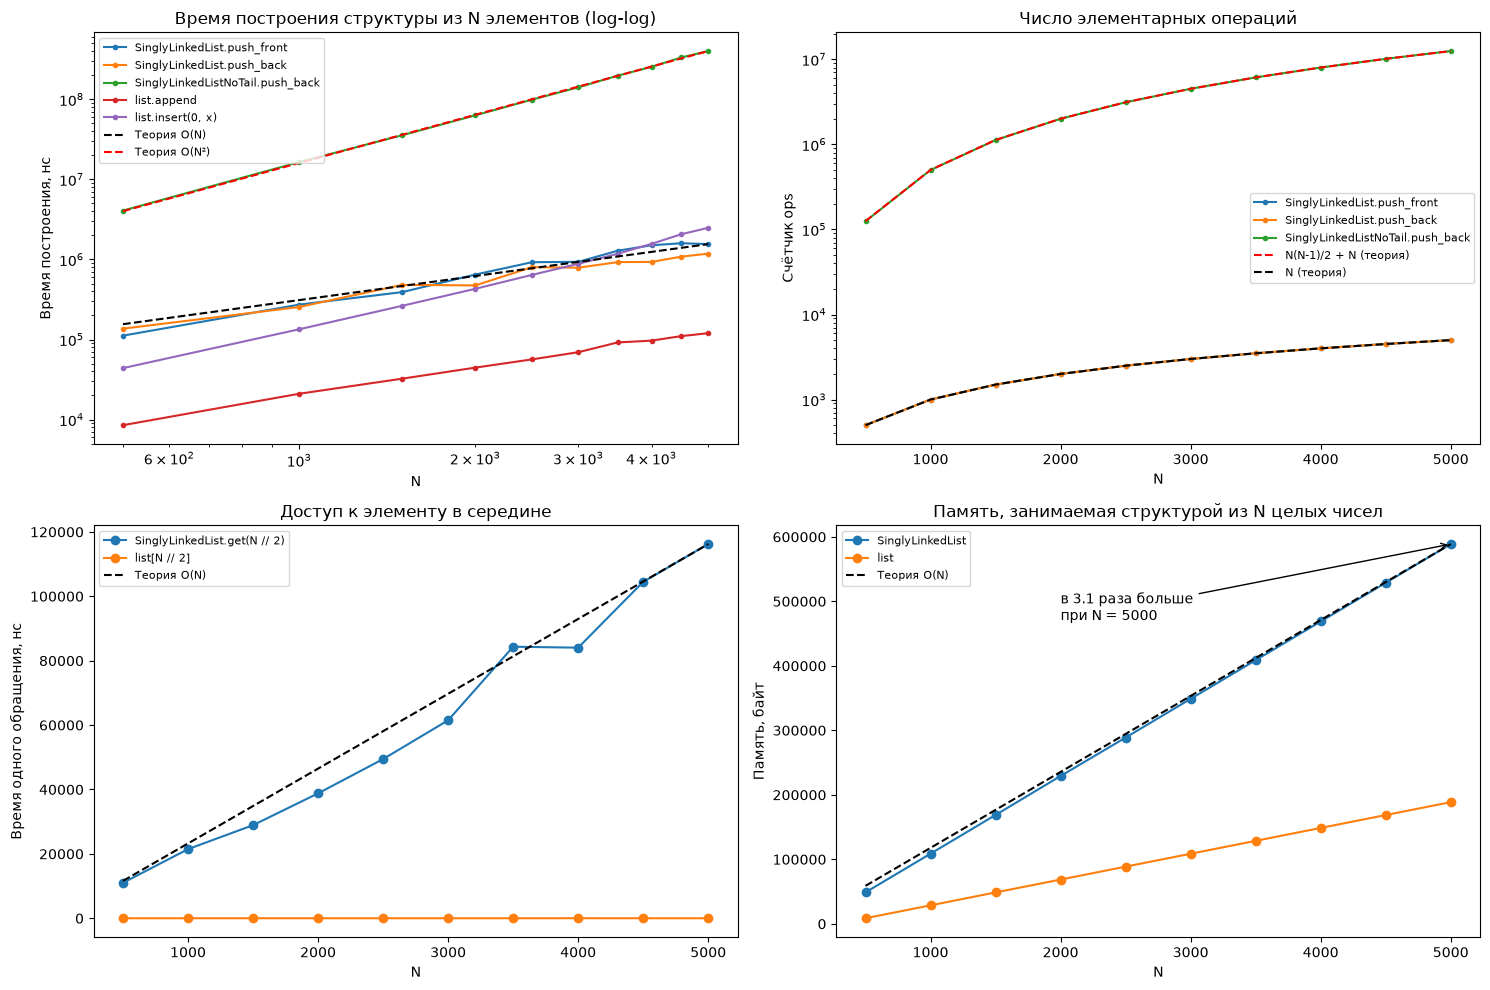

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 10. время построения
ax = axes[0, 0]
for name in METHODS1:
    ax.plot(SIZES1, time1[name], marker="o", ms=3, label=name)
ax.plot(
    SIZES1,
    theory(SIZES1, time1["SinglyLinkedList.push_front"], 1),
    "k--",
    label="Теория O(N)",
)
ax.plot(
    SIZES1,
    theory(SIZES1, time1["SinglyLinkedListNoTail.push_back"], 2),
    "r--",
    label="Теория O(N²)",
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("N")
ax.set_ylabel("Время построения, нс")
ax.set_title("Время построения структуры из N элементов (log-log)")
ax.legend(fontsize=8)

# 11. количество операций
ax = axes[0, 1]
for name in [
    "SinglyLinkedList.push_front",
    "SinglyLinkedList.push_back",
    "SinglyLinkedListNoTail.push_back",
]:
    ax.plot(SIZES1, ops1[name], marker="o", ms=3, label=name)
ax.plot(
    SIZES1, [N * (N - 1) / 2 + N for N in SIZES1], "r--", label="N(N-1)/2 + N (теория)"
)
ax.plot(SIZES1, SIZES1, "k--", label="N (теория)")
ax.set_yscale("log")
ax.set_xlabel("N")
ax.set_ylabel("Счётчик ops")
ax.set_title("Число элементарных операций")
ax.legend(fontsize=8)

# 12. доступ к середине
ax = axes[1, 0]
ax.plot(SIZES1, mid_ll_t, marker="o", label="SinglyLinkedList.get(N // 2)")
ax.plot(SIZES1, mid_list_t, marker="o", label="list[N // 2]")
ax.plot(SIZES1, theory(SIZES1, mid_ll_t, 1), "k--", label="Теория O(N)")
ax.set_xlabel("N")
ax.set_ylabel("Время одного обращения, нс")
ax.set_title("Доступ к элементу в середине")
ax.legend(fontsize=8)

# 13. память
ax = axes[1, 1]
ax.plot(SIZES1, mem_ll, marker="o", label="SinglyLinkedList")
ax.plot(SIZES1, mem_list, marker="o", label="list")
ax.plot(SIZES1, theory(SIZES1, mem_ll, 1), "k--", label="Теория O(N)")
ax.annotate(
    f"в {mem_ratio:.1f} раза больше\nпри N = 5000",
    xy=(SIZES1[-1], mem_ll[-1]),
    xytext=(SIZES1[3], mem_ll[-1] * 0.8),
    arrowprops={"arrowstyle": "->"},
)
ax.set_xlabel("N")
ax.set_ylabel("Память, байт")
ax.set_title("Память, занимаемая структурой из N целых чисел")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### Анализ результатов + ответы на вопросы

1. Сравните теоретическую асимптотику с экспериментальными данными. Совпадает ли форма кривых?
2. Почему `push_back` без `tail` дал квадратичное суммарное время? Сколько операций он выполнил при N = 5000 и как это согласуется с формулой $\frac{N(N-1)}{2}$?
3. И `list.insert(0, x)`, и `SinglyLinkedListNoTail.push_back` квадратичны. Какой из них быстрее на практике и почему?
4. Во сколько раз связный список занимает больше памяти, чем `list`? Из чего складывается память одного узла?
5. В каких задачах связный список действительно выгоднее динамического массива?

Ответы (задание 1)

1. Совпадает. push_front, push_back с tail и list.append линейны (наклон 1 на log-log), NoTail.push_back и list.insert(0, x) квадратичны (наклон 2). ops у push_front/push_back с tail равен N. get(N // 2) линейно растёт с N, list[N // 2] от N не зависит.

2. i-е добавление идёт по i-1 ссылке, в сумме N(N-1)/2 переходов. При N = 5000 это 12 497 500, счётчик показал 12 497 501 = (N-1)(N-2)/2 + N: переходы плюс N созданных узлов. Отличие только в O(N) слагаемых.

3. При N = 5000 insert(0, x) занял около 4 мс, NoTail.push_back около 666 мс, то есть в 160 раз дольше. Шагов у обоих порядка N^2/2, но insert сдвигает массив одним memmove в C, а обход списка это N^2/2 итераций цикла на Python с переходом по узлам, разбросанным по памяти.

4. При N = 5000 список занял 588 776 Б, list 188 664 Б: в 3.1 раза больше. Узел это объект Python (getsizeof(Node(0)) = 48 Б) плюс объект-число 28 Б, плюс две ссылки value и next. В list на элемент идёт только ссылка 8 Б и то же число 28 Б.

5. Когда вставки и удаления идут в начале или в середине по уже известному узлу, индексы не нужны, перевыделения недопустимы (реальное время) или на узлы ссылаются снаружи и двигать их нельзя. Ещё стеки, очереди, списки смежности, цепочки в хеш-таблицах. Иначе массив выигрывает по кэшу и памяти.

# Задание 2 (2 балла). Стек и очередь

**Стек** — структура LIFO (последним пришёл — первым ушёл): `push`, `pop`, `peek`.

**Очередь** — структура FIFO (первым пришёл — первым ушёл): `enqueue`, `dequeue`, `peek`.

Обе структуры можно реализовать как на массиве, так и на связном списке. Важно выбрать, с какого конца добавлять и удалять, чтобы все операции работали за $O(1)$.

### Предварительная подготовка

1. Реализовать четыре класса с единым интерфейсом. Методы `pop`/`dequeue`/`peek` на пустой структуре должны бросать `IndexError`.

| Класс | Основа | Методы |
|---|---|---|
| `ArrayStack` | `list` | `push`, `pop`, `peek`, `is_empty`, `__len__` |
| `LinkedStack` | собственные узлы `Node` | `push`, `pop`, `peek`, `is_empty`, `__len__` |
| `LinkedQueue` | собственные узлы, `head` + `tail` | `enqueue`, `dequeue`, `peek`, `is_empty`, `__len__` |
| `NaiveListQueue` | `list`, удаление через `pop(0)` | `enqueue`, `dequeue`, `peek`, `is_empty`, `__len__` |

2. Используя **ваш** `LinkedStack`, реализовать:
   * `is_valid_brackets(s)` — проверку правильности скобочной последовательности из `()[]{}`;
   * `eval_rpn(tokens)` — вычисление выражения в обратной польской записи (операции `+ - * /`, деление — с отбрасыванием дробной части к нулю).
3. Для каждой операции каждого класса указать асимптотику и обосновать её. Объяснить, почему в `LinkedQueue` добавлять нужно в хвост, а удалять из головы, а не наоборот.

In [11]:
class ArrayStack:
    def __init__(self):
        self._data = []

    def push(self, x):
        self._data.append(x)

    def pop(self):
        if not self._data:
            raise IndexError("pop from empty stack")
        return self._data.pop()

    def peek(self):
        if not self._data:
            raise IndexError("peek from empty stack")
        return self._data[-1]

    def is_empty(self):
        return not self._data

    def __len__(self):
        return len(self._data)

class LinkedStack:
    def __init__(self):
        self.head = None
        self.size = 0

    def push(self, x):
        self.head = Node(x, self.head)
        self.size += 1

    def pop(self):
        if self.head is None:
            raise IndexError("pop from empty stack")
        node = self.head
        self.head = node.next
        self.size -= 1
        return node.value

    def peek(self):
        if self.head is None:
            raise IndexError("peek from empty stack")
        return self.head.value

    def is_empty(self):
        return self.head is None

    def __len__(self):
        return self.size

class LinkedQueue:
    """Добавляем в хвост, извлекаем из головы."""

    def __init__(self):
        self.head = None
        self.tail = None
        self.size = 0

    def enqueue(self, x):
        node = Node(x)
        if self.tail is None:
            self.head = self.tail = node
        else:
            self.tail.next = node
            self.tail = node
        self.size += 1

    def dequeue(self):
        if self.head is None:
            raise IndexError("dequeue from empty queue")
        node = self.head
        self.head = node.next
        if self.head is None:
            self.tail = None
        self.size -= 1
        return node.value

    def peek(self):
        if self.head is None:
            raise IndexError("peek from empty queue")
        return self.head.value

    def is_empty(self):
        return self.head is None

    def __len__(self):
        return self.size

class NaiveListQueue:
    def __init__(self):
        self._data = []

    def enqueue(self, x):
        self._data.append(x)

    def dequeue(self):
        if not self._data:
            raise IndexError("dequeue from empty queue")
        return self._data.pop(0)

    def peek(self):
        if not self._data:
            raise IndexError("peek from empty queue")
        return self._data[0]

    def is_empty(self):
        return not self._data

    def __len__(self):
        return len(self._data)

def is_valid_brackets(s):
    pairs = {")": "(", "]": "[", "}": "{"}
    st = LinkedStack()
    for ch in s:
        if ch in "([{":
            st.push(ch)
        elif ch in pairs:
            if st.is_empty() or st.pop() != pairs[ch]:
                return False
    return st.is_empty()

def eval_rpn(tokens):
    st = LinkedStack()
    for t in tokens:
        if t in ("+", "-", "*", "/"):
            b = st.pop()
            a = st.pop()
            if t == "+":
                st.push(a + b)
            elif t == "-":
                st.push(a - b)
            elif t == "*":
                st.push(a * b)
            else:  # деление с отбрасыванием к нулю
                q = abs(a) // abs(b)
                st.push(q if (a < 0) == (b < 0) else -q)
        else:
            st.push(int(t))
    return st.pop()

**Асимптотика операций**

| Класс | `push` / `enqueue` | `pop` / `dequeue` | `peek`, `is_empty`, `__len__` |
|---|---|---|---|
| `ArrayStack` | $O(1)$ амортизированно | $O(1)$ | $O(1)$ |
| `LinkedStack` | $O(1)$ | $O(1)$ | $O(1)$ |
| `LinkedQueue` | $O(1)$ | $O(1)$ | $O(1)$ |
| `NaiveListQueue` | $O(1)$ амортизированно | $O(n)$ | $O(1)$ |

**Обоснование.**
* `ArrayStack`: `list.append`/`list.pop()` работают с концом массива; иногда `append` вызывает перевыделение памяти (амортизированное $O(1)$, см. задание 3), `pop()` — $O(1)$.
* `LinkedStack`: и `push`, и `pop` меняют только `head` — константное число действий в худшем случае.
* `LinkedQueue`: `enqueue` присоединяет узел к `tail`, `dequeue` отцепляет `head` — оба конца известны, обе операции $O(1)$ в худшем случае.
* `NaiveListQueue`: `pop(0)` удаляет первый элемент массива и сдвигает все остальные $n-1$ ссылок на одну позицию влево — $\Theta(n)$ (`memmove`).
* `peek`, `is_empty`, `__len__` — чтение поля или элемента по индексу, $O(1)$.

**Почему в `LinkedQueue` добавляем в хвост, а извлекаем из головы.** Для удаления из головы достаточно сдвинуть `head` (узел знает следующий). Для удаления из хвоста пришлось бы найти *предпоследний* узел, а в односвязном списке это обход за $O(n)$. Поэтому разворот (вставка в голову, извлечение из хвоста) сделал бы `dequeue` линейным; добавление же в хвост при наличии `tail` — $O(1)$.

`is_valid_brackets` и `eval_rpn` работают за $O(n)$: каждый символ/токен обрабатывается один раз, операции стека — $O(1)$.

In [12]:
for S in (ArrayStack, LinkedStack):
    s = S()
    assert s.is_empty() and len(s) == 0
    for x in [1, 2, 3]:
        s.push(x)
    assert s.peek() == 3 and len(s) == 3
    assert [s.pop(), s.pop(), s.pop()] == [3, 2, 1]
    try:
        s.pop()
        assert False
    except IndexError:
        pass

for Q in (LinkedQueue, NaiveListQueue):
    q = Q()
    assert q.is_empty()
    for x in [1, 2, 3]:
        q.enqueue(x)
    assert q.peek() == 1 and len(q) == 3
    assert q.dequeue() == 1
    q.enqueue(4)
    assert [q.dequeue(), q.dequeue(), q.dequeue()] == [2, 3, 4]
    assert q.is_empty()
    q.enqueue(5)  # проверка после опустошения
    assert q.dequeue() == 5
    try:
        q.dequeue()
        assert False
    except IndexError:
        pass

assert (
    is_valid_brackets("()[]{}")
    and is_valid_brackets("{[()()]}")
    and is_valid_brackets("")
)
assert (
    not is_valid_brackets("(]")
    and not is_valid_brackets("([)]")
    and not is_valid_brackets("((")
)
assert not is_valid_brackets(")")
assert eval_rpn(["2", "1", "+", "3", "*"]) == 9
assert eval_rpn(["4", "13", "5", "/", "+"]) == 6
assert (
    eval_rpn(["10", "6", "9", "3", "+", "-11", "*", "/", "*", "17", "+", "5", "+"])
    == 22
)
print("Все проверки пройдены!")

Все проверки пройдены!


### Провести эксперименты

4. Взять N от 5000 до 50000 с шагом 5000.
5. Для стеков (`ArrayStack`, `LinkedStack`) измерить среднее время серии «N раз `push`, затем N раз `pop`».
6. Для очередей (`LinkedQueue`, `NaiveListQueue`, `collections.deque`, `queue.Queue`) измерить среднее время серии «N раз добавить, затем N раз извлечь».
7. Сгенерировать правильные скобочные последовательности длины от 10 000 до 100 000 и измерить время `is_valid_brackets`.

In [13]:
import queue
from collections import deque

SIZES2 = list(range(5000, 50001, 5000))

def stack_series(S):
    def run(N):
        s = S()
        for i in range(N):
            s.push(i)
        for _ in range(N):
            s.pop()

    return run

def queue_series(Q):
    def run(N):
        q = Q()
        for i in range(N):
            q.enqueue(i)
        for _ in range(N):
            q.dequeue()

    return run

def deque_series(N):
    q = deque()
    for i in range(N):
        q.append(i)
    for _ in range(N):
        q.popleft()

def std_queue_series(N):
    q = queue.Queue()
    for i in range(N):
        q.put(i)
    for _ in range(N):
        q.get()

stack_times = {
    "ArrayStack": [measure_series(stack_series(ArrayStack), N, 7) for N in SIZES2],
    "LinkedStack": [measure_series(stack_series(LinkedStack), N, 7) for N in SIZES2],
}
queue_runs = {
    "LinkedQueue": queue_series(LinkedQueue),
    "NaiveListQueue": queue_series(NaiveListQueue),
    "collections.deque": deque_series,
    "queue.Queue": std_queue_series,
}
queue_times = {
    name: [measure_series(f, N, 7) for N in SIZES2] for name, f in queue_runs.items()
}

for d in (stack_times, queue_times):
    for name, ts in d.items():
        print(f"{name:20s} N=50000: {ts[-1] / 1e6:9.2f} мс")

# скобочные последовательности
def gen_brackets(L, rng):
    close = {"(": ")", "[": "]", "{": "}"}
    res, st = [], []
    for i in range(L):
        remaining = L - i
        if not st or (len(st) < remaining and rng.random() < 0.5):
            ch = rng.choice("([{")
            st.append(ch)
            res.append(ch)
        else:
            res.append(close[st.pop()])
    return "".join(res)

rng = random.Random(1)
LENS = list(range(10_000, 100_001, 10_000))
brackets = {L: gen_brackets(L, rng) for L in LENS}
assert all(is_valid_brackets(s) for s in brackets.values())
brackets_times = [
    measure_series(lambda L: is_valid_brackets(brackets[L]), L, 7) for L in LENS
]
print("is_valid_brackets, L=100000: %.2f мс" % (brackets_times[-1] / 1e6))

ArrayStack           N=50000:      6.66 мс
LinkedStack          N=50000:     33.41 мс
LinkedQueue          N=50000:     22.06 мс
NaiveListQueue       N=50000:    156.07 мс
collections.deque    N=50000:      3.79 мс
queue.Queue          N=50000:     59.15 мс
is_valid_brackets, L=100000: 17.63 мс


### Построить графики

8. На одном графике — время для двух стеков. Теоретическая кривая $O(N)$ — пунктиром.
9. На одном графике — время для четырёх очередей. Теоретические кривые $O(N)$ и $O(N^2)$ — пунктиром.
10. Время `is_valid_brackets` от длины строки с теоретической кривой.

**Требования к графикам:**

Сделайте
* Подписи осей
* Заголовок
* Легенду с пояснением всех линий
* Теоретические кривые — пунктирной линией

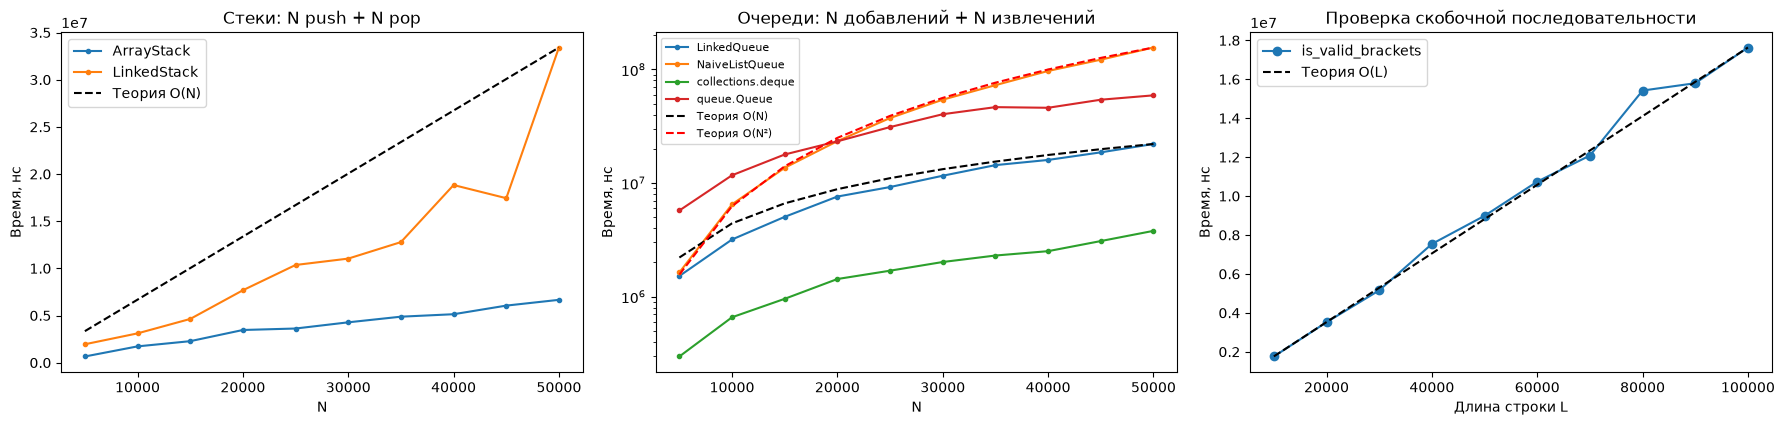

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

ax = axes[0]
for name, ts in stack_times.items():
    ax.plot(SIZES2, ts, marker="o", ms=3, label=name)
ax.plot(
    SIZES2, theory(SIZES2, stack_times["LinkedStack"], 1), "k--", label="Теория O(N)"
)
ax.set_xlabel("N")
ax.set_ylabel("Время, нс")
ax.set_title("Стеки: N push + N pop")
ax.legend()

ax = axes[1]
for name, ts in queue_times.items():
    ax.plot(SIZES2, ts, marker="o", ms=3, label=name)
ax.plot(
    SIZES2, theory(SIZES2, queue_times["LinkedQueue"], 1), "k--", label="Теория O(N)"
)
ax.plot(
    SIZES2,
    theory(SIZES2, queue_times["NaiveListQueue"], 2),
    "r--",
    label="Теория O(N²)",
)
ax.set_yscale("log")
ax.set_xlabel("N")
ax.set_ylabel("Время, нс")
ax.set_title("Очереди: N добавлений + N извлечений")
ax.legend(fontsize=8)

ax = axes[2]
ax.plot(LENS, brackets_times, marker="o", label="is_valid_brackets")
ax.plot(LENS, theory(LENS, brackets_times, 1), "k--", label="Теория O(L)")
ax.set_xlabel("Длина строки L")
ax.set_ylabel("Время, нс")
ax.set_title("Проверка скобочной последовательности")
ax.legend()

plt.tight_layout()
plt.show()

### Анализ результатов + ответы на вопросы

1. Сравните теоретическую асимптотику с экспериментальными данными. Совпадает ли форма кривых?
2. Какой стек быстрее — на `list` или на узлах? Почему, если оба работают за $O(1)$?
3. Почему `NaiveListQueue` квадратичен, хотя при небольших N может работать быстро?
4. Почему `queue.Queue` заметно медленнее `deque`? Когда его всё-таки стоит использовать?
5. Какую из реализованных очередей вы бы выбрали для реальной программы и почему?

Ответы (задание 2)

1. Совпадает. Оба стека, LinkedQueue, deque и queue.Queue линейны по N, NaiveListQueue в серии N добавлений и N извлечений квадратична. is_valid_brackets линейна по длине (около 25 мс при L = 10^5).

2. ArrayStack быстрее: при N = 50000 около 9 мс против 45 мс у LinkedStack (в 5 раз). Асимптотика одна, разница в константе: push в LinkedStack создаёт объект Node и вызывает __init__, а list.append и list.pop это методы на C без аллокации на каждый элемент.

3. pop(0) сдвигает все оставшиеся элементы, это O(n), на N извлечений выходит O(N^2). Но сдвиг это один memmove, и при малых N он дешевле создания узлов в LinkedQueue. Квадрат начинает доминировать только на больших N. Если очередь короткая (enqueue, dequeue по одному), pop(0) остаётся дешёвым, это видно в эксперименте 4.2.

4. queue.Queue потокобезопасна: каждая операция берёт мьютекс, работает с условными переменными и считает задачи. Отсюда в 16 раз медленнее deque (84 мс против 5 мс при N = 50000). Нужна при обмене данными между потоками, где важны блокирующие get и put, таймауты, лимит размера. В одном потоке хватает deque.

5. collections.deque: O(1) с обоих концов и быстрее всех. Из своих LinkedQueue, у неё нет квадратичной деградации. NaiveListQueue только для коротких очередей.

# Задание 3 (3 балла). Динамический массив и амортизационный анализ

**Динамический массив** хранит блок памяти ёмкостью `capacity`, в котором заняты первые `size` ячеек. Когда места нет, выделяется новый блок большего размера и все элементы копируются.

* При **умножении** ёмкости на $\alpha > 1$ добавление в конец работает за амортизированное $O(1)$ (суммарно копирований $O\!\left(\frac{n}{\alpha - 1}\right)$).
* При **увеличении на константу** $c$ — за амортизированное $O(n)$ (суммарно $\approx \frac{n^2}{2c}$ копирований).
* Для удвоения работает потенциал $\Phi = 2\cdot\text{size} - \text{capacity}$, и $\hat{c}_i = c_i + \Delta\Phi \le 3$.
* Уменьшать ёмкость вдвое нужно, когда массив заполнен на $\frac14$, а не на $\frac12$, иначе возникает «пробуксовка».

### Предварительная подготовка

1. Реализовать класс `DynamicArray(growth=2.0, additive=None, shrink="quarter", initial_capacity=1)`:
   * если `additive` задан, новая ёмкость = `capacity + additive`, иначе `max(capacity + 1, int(capacity * growth))`;
   * `shrink` принимает значения `"quarter"` (сжимать вдвое при `size <= capacity // 4`), `"half"` (сжимать вдвое при `size <= capacity // 2`) или `None` (не сжимать); ёмкость не опускается ниже `initial_capacity`;
   * хранилище — **только** список фиксированной длины `[None] * capacity`; методы `append`/`insert`/`pop` встроенного списка для хранилища использовать **нельзя**;
   * методы: `append(x)`, `pop()`, `__getitem__`, `__setitem__`, `__len__`, свойство `capacity`;
   * счётчики: `self.writes` (запись нового элемента), `self.copies` (копирование при изменении ёмкости), `self.last_cost` — стоимость последней операции (`1` + число копирований для `append`; `1` + число копирований для `pop`).
2. Доказать **тремя методами** (групповой, бухгалтерский, потенциалов), что амортизированная стоимость `append` при удвоении — $O(1)$.
3. Доказать, что при `additive = c` суммарная стоимость $n$ операций — $\Theta(n^2)$.
4. Привести последовательность операций, на которой правило `"half"` даёт $\Theta(n)$ на каждую операцию.

In [15]:
class DynamicArray:
    def __init__(
        self,
        growth=2.0,
        additive=None,
        shrink: str | None = "quarter",
        initial_capacity=1,
    ):
        self.growth = growth
        self.additive = additive
        self.shrink = shrink
        self.initial_capacity = initial_capacity
        self._data = [None] * initial_capacity  # хранилище фиксированной длины
        self._size = 0
        self.writes = 0
        self.copies = 0
        self.last_cost = 0

    @property
    def capacity(self):
        return len(self._data)

    def __len__(self):
        return self._size

    def _check(self, i):
        if not 0 <= i < self._size:
            raise IndexError("index out of range")

    def __getitem__(self, i):
        self._check(i)
        return self._data[i]

    def __setitem__(self, i, x):
        self._check(i)
        self._data[i] = x

    def _resize(self, new_capacity):
        """Выделяет новый блок и копирует в него size элементов. Возвращает число копирований."""
        new_data = [None] * new_capacity
        new_data[: self._size] = self._data[: self._size]  # копирование size элементов
        self._data = new_data
        self.copies += self._size
        return self._size

    def append(self, x):
        copied = 0
        if self._size == self.capacity:
            if self.additive is not None:
                new_capacity = self.capacity + self.additive
            else:
                new_capacity = max(self.capacity + 1, int(self.capacity * self.growth))
            copied = self._resize(new_capacity)
        self._data[self._size] = x
        self._size += 1
        self.writes += 1
        self.last_cost = 1 + copied

    def pop(self):
        if self._size == 0:
            raise IndexError("pop from empty array")
        self._size -= 1
        x = self._data[self._size]
        self._data[self._size] = None
        copied = 0
        # сжимаем при заполненности 1/4, а не 1/2: после сжатия в 2 раза массив
        # заполнен на 1/2, и до следующего сжатия или расширения нужно ещё Θ(size) операций
        limits = {"quarter": self.capacity // 4, "half": self.capacity // 2}
        limit = limits.get(self.shrink) if self.shrink is not None else None
        if limit is not None and self._size <= limit:
            new_capacity = max(self.initial_capacity, self.capacity // 2)
            if new_capacity < self.capacity:
                copied = self._resize(new_capacity)
        self.last_cost = 1 + copied
        return x

### Доказательства

Пусть $n$ раз вызывается `append` при удвоении ёмкости (начальная ёмкость 1). Перевыделение происходит в момент, когда `size = capacity = 2^j`, и стоит $2^j$ копирований.

**2а. Групповой метод.** Перевыделения происходят при $\text{size} = 1, 2, 4, \dots, 2^m$, где $2^m \le n-1$. Суммарное число копирований
$$\sum_{j=0}^{m} 2^j = 2^{m+1}-1 \le 2(n-1) - 1 < 2n.$$
Ещё $n$ единиц стоят сами записи, поэтому суммарная стоимость $n$ операций $< 3n$, средняя — меньше $3 = O(1)$.

**2б. Метод бухгалтерского учёта.** Берём за каждый `append` по 3 монеты: 1 монета оплачивает саму запись, 2 монеты кладём «на счёт» только что записанного элемента. Пусть массив только что расширили до ёмкости $2m$; в нём $m$ элементов, и накопленных монет нет. Следующие $m$ добавлений (пока массив не заполнится) положат на счёт по 2 монеты, итого $2m$ — ровно столько стоит копирование $2m$ элементов при следующем расширении. Значит, на любой момент баланс неотрицателен и каждый `append` амортизированно стоит $3 = O(1)$.

**2в. Метод потенциалов.** $\Phi = 2\cdot\text{size} - \text{capacity}$. Начальное $\Phi_0 = -1$ (ёмкость 1), после этого размер всегда больше половины ёмкости, т.е. $\Phi \ge 0 > \Phi_0$, поэтому $\sum \hat c_i \ge \sum c_i$.
* Обычный `append` ($c=1$): $\Delta\Phi = 2$, $\hat c = 1 + 2 = 3$.
* `append` с перевыделением при $\text{size}=\text{capacity}=m$: $c = m + 1$; до операции $\Phi = 2m - m = m$, после — $\text{size}=m+1$, $\text{capacity}=2m$, $\Phi = 2(m+1) - 2m = 2$. Тогда $\hat c = (m+1) + 2 - m = 3$.
* Первый `append` (ёмкость 1, $\Phi_0=-1 \to \Phi_1 = 1$): $\hat c = 1 + 2 = 3$.

Итак, $\hat c_i \le 3$ для всех $i$ — амортизированная стоимость $O(1)$ (в эксперименте 3.1 это проверяется `assert`ом).

**3. Увеличение на константу $c$ даёт $\Theta(n^2)$.** Перевыделения происходят при $\text{size} = c, 2c, \dots, Jc$, где $J = \lfloor (n-1)/c \rfloor$; $j$-е копирует $jc$ элементов:
$$\text{copies} = c\sum_{j=1}^{J} j = \frac{c\,J(J+1)}{2} \approx \frac{n^2}{2c}.$$
Нижняя оценка: $J \ge \frac{n}{c}-1$, поэтому при $n \ge 2c$ получаем $\text{copies} \ge \frac{(n-c)\,n}{2c} \ge \frac{n^2}{4c}$. Для фиксированной $c$ это $\Theta(n^2)$; суммарная стоимость $n$ операций $\Theta(n^2)$, амортизированная — $\Theta(n)$ на операцию.

**4. Пробуксовка при сжатии на половине.** Заполним массив до $n = 2^k$ элементов (ёмкость $2^k$). Теперь чередуем `append`, `pop`:
* `append`: массив полон → расширение до $2^{k+1}$, копируем $2^k$ элементов; размер $2^k+1$;
* `pop`: размер становится $2^k \le \text{capacity}/2 = 2^k$ → правило `"half"` сжимает до $2^k$, снова копируем $2^k$ элементов.

И каждая операция стоит $\Theta(n)$, хотя размер почти не меняется. При правиле `"quarter"` после сжатия до $\text{capacity}/2$ массив заполнен ровно наполовину: до следующего перевыделения нужно не менее $\text{capacity}/4$ операций, которые оплачивают копирование — амортизированная стоимость снова $O(1)$.

In [16]:
a = DynamicArray()
for i in range(10):
    a.append(i)
assert len(a) == 10 and [a[i] for i in range(10)] == list(range(10))
assert a.capacity == 16
assert a.copies == 1 + 2 + 4 + 8 and a.writes == 10
a[3] = 100
assert a[3] == 100
try:
    a[10]
    assert False
except IndexError:
    pass

a.append(10)
assert a.last_cost == 1
b = DynamicArray()
for i in range(8):
    b.append(i)
b.append(8)
assert b.last_cost == 1 + 8  # 8 копирований + запись

c = DynamicArray(additive=10, initial_capacity=10)
for i in range(35):
    c.append(i)
assert c.capacity == 40 and c.copies == 10 + 20 + 30

d = DynamicArray(shrink="quarter")
for i in range(16):
    d.append(i)
assert d.capacity == 16
for _ in range(12):
    d.pop()
assert len(d) == 4 and d.capacity == 8 and [d[i] for i in range(4)] == [0, 1, 2, 3]

e = DynamicArray(shrink=None)
for i in range(16):
    e.append(i)
for _ in range(16):
    e.pop()
assert e.capacity == 16 and len(e) == 0
try:
    e.pop()
    assert False
except IndexError:
    pass
print("Все проверки пройдены!")

Все проверки пройдены!


### Провести эксперименты

**Эксперимент 3.1. Стоимость отдельных операций.**

5. Выполнить $n = 2000$ операций `append` для `DynamicArray()` и записать `last_cost` каждой операции, суммарную стоимость и среднюю стоимость.
6. Для каждой операции вычислить потенциал $\Phi = 2\cdot\text{size} - \text{capacity}$ и амортизированную стоимость $\hat{c}_i = c_i + \Phi_i - \Phi_{i-1}$. Проверить через `assert`, что $\hat{c}_i \le 3$ (первую операцию можно пропустить).

**Эксперимент 3.2. Коэффициент роста.**

7. Для N от 1000 до 50000 с шагом 1000 и стратегий `growth` ∈ {1.25, 1.5, 2, 3}, `additive` ∈ {10, 100} подсчитать:
   * суммарное число копирований `copies`;
   * долю неиспользуемой памяти $\frac{\text{capacity} - \text{size}}{\text{capacity}}$ после N добавлений;
   * среднее время N добавлений (не менее 5 повторных замеров).

**Эксперимент 3.3. Пробуксовка.**

8. Для правил `"half"` и `"quarter"`: заполнить массив до размера $2^k$ ($k$ от 8 до 14), затем выполнить 1000 пар операций «`append`, `pop`». Подсчитать суммарное число копирований за эти 2000 операций.

**Эксперимент 3.4. Встроенный `list`.**

9. Добавлять в пустой `list` элементы по одному (до 10 000) и с помощью `sys.getsizeof` зафиксировать моменты, когда меняется размер выделенной памяти. Оценить коэффициент роста CPython.
10. Измерить `perf_counter_ns()` время **каждой** из 100 000 операций `list.append` и найти номера операций с аномально большим временем.

In [17]:
import itertools

# ---------- Эксперимент 3.1 ----------
N31 = 2000
arr = DynamicArray()
costs31, cum31, amort31 = [], [], []
total31 = 0
phi_prev = 2 * len(arr) - arr.capacity
for i in range(N31):
    arr.append(i)
    c = arr.last_cost
    phi = 2 * len(arr) - arr.capacity
    amort31.append(c + phi - phi_prev)
    phi_prev = phi
    total31 += c
    costs31.append(c)
    cum31.append(total31)
    assert amort31[-1] <= 3
print(
    "n =",
    N31,
    " max c_i =",
    max(costs31),
    " сумма =",
    total31,
    " среднее =",
    total31 / N31,
    " (граница 3n =",
    3 * N31,
    ")",
)
print("max амортизированной стоимости:", max(amort31))

# ---------- Эксперимент 3.2 ----------
N_GRID32 = list(range(1000, 50001, 1000))
STRATEGIES = {
    "x1.25": {"growth": 1.25},
    "x1.5": {"growth": 1.5},
    "x2": {"growth": 2},
    "x3": {"growth": 3},
    "+10": {"additive": 10},
    "+100": {"additive": 100},
}
copies32, waste32, time32 = {}, {}, {}
checkpoints = set(N_GRID32)
for name, kw in STRATEGIES.items():
    a = DynamicArray(shrink=None, **kw)
    cps, ws = [], []
    for i in range(
        1, N_GRID32[-1] + 1
    ):  # один прогон до max N: состояние после N добавлений одно и то же
        a.append(i)
        if i in checkpoints:
            cps.append(a.copies)
            ws.append((a.capacity - len(a)) / a.capacity)
    copies32[name], waste32[name] = cps, ws

    def run(N, kw=kw):
        b = DynamicArray(shrink=None, **kw)
        for i in range(N):
            b.append(i)

    time32[name] = [
        measure_series(run, N, repeats=7) for N in N_GRID32
    ]  # 5 замеров после отбрасывания min/max

for name in STRATEGIES:
    print(
        f"{name:6s} N=50000: copies = {copies32[name][-1]:>10d}, доля пустой памяти = {waste32[name][-1]:.3f}, "
        f"время = {time32[name][-1] / 1e6:8.2f} мс"
    )
print(
    "средняя доля пустой памяти (мультипликативные):",
    {n: round(float(np.mean(waste32[n])), 3) for n in ["x1.25", "x1.5", "x2", "x3"]},
)

# ---------- Эксперимент 3.3 ----------
K_RANGE = list(range(8, 15))
thrash = {"half": [], "quarter": []}
for rule in thrash:  # noqa: PLC0206 иначе ruff ругался что по ключам итерируюсь
    for k in K_RANGE:
        a = DynamicArray(shrink=rule)
        for i in range(2 ** k):
            a.append(i)
        assert a.capacity == 2 ** k
        before = a.copies
        for _ in range(1000):
            a.append(0)
            a.pop()
        thrash[rule].append(a.copies - before)
print("копирования за 2000 операций (k = 8..14):")
for rule in thrash:  # noqa: PLC0206 сейм тут
    print(f"  {rule:8s}", thrash[rule])

# ---------- Эксперимент 3.4 ----------
base = sys.getsizeof([])
lst, sizes34, jumps = [], [], []
prev = base
for i in range(1, 10_001):
    lst.append(i)
    s = sys.getsizeof(lst)
    sizes34.append(s)
    if s != prev:
        jumps.append((i, s))
        prev = s
caps34 = [(s - base) // 8 for _, s in jumps]
ratios34 = [c2 / c1 for c1, c2 in itertools.pairwise(caps34)]
print("первые перевыделения (длина, байт):", jumps[:8])
print("ёмкости на последних скачках:", caps34[-5:])
print("коэффициенты роста на последних скачках:", [round(r, 3) for r in ratios34[-5:]])
print(
    "медиана отношения ёмкостей при ёмкости > 100:",
    round(float(np.median([r for c, r in zip(caps34, ratios34) if c > 100])), 4),
)

M34 = 100_000
pc = time.perf_counter_ns
append_ns = np.empty(M34, dtype=np.int64)
lst, realloc_idx = (
    [],
    [],
)  # realloc_idx — 0-based номера операций, на которых изменился размер
prev = base
for i in range(M34):
    t0 = pc()
    lst.append(i)
    append_ns[i] = pc() - t0
    s = sys.getsizeof(lst)
    if s != prev:
        realloc_idx.append(i)
        prev = s
median_ns = float(np.median(append_ns))
THRESH = 20 * median_ns
anomal = np.flatnonzero(append_ns > THRESH)
hit = np.intersect1d(anomal, realloc_idx)
print(f"медиана времени append = {median_ns:.0f} нс, порог = {THRESH:.0f} нс")
print(
    f"аномальных операций: {len(anomal)}, перевыделений памяти: {len(realloc_idx)}, совпало: {len(hit)}"
)
print("первые 15 аномальных номеров:", anomal[:15].tolist())
print("максимальное время одного append: %.1f мкс" % (append_ns.max() / 1e3))

n = 2000  max c_i = 1025  сумма = 4047  среднее = 2.0235  (граница 3n = 6000 )
max амортизированной стоимости: 3
x1.25  N=50000: copies =     246853, доля пустой памяти = 0.190, время =    11.86 мс
x1.5   N=50000: copies =     122904, доля пустой памяти = 0.186, время =    10.64 мс
x2     N=50000: copies =      65535, доля пустой памяти = 0.237, время =    11.33 мс
x3     N=50000: copies =      29524, доля пустой памяти = 0.153, время =     9.31 мс
+10    N=50000: copies =  124980000, доля пустой памяти = 0.000, время =   938.89 мс
+100   N=50000: copies =   12475500, доля пустой памяти = 0.000, время =    88.97 мс
средняя доля пустой памяти (мультипликативные): {'x1.25': 0.097, 'x1.5': 0.176, 'x2': 0.274, 'x3': 0.378}
копирования за 2000 операций (k = 8..14):
  half     [512000, 1024000, 2048000, 4096000, 8192000, 16384000, 32768000]
  quarter  [256, 512, 1024, 2048, 4096, 8192, 16384]
первые перевыделения (длина, байт): [(1, 88), (5, 120), (9, 184), (17, 248), (25, 312), (33, 376), (

### Построить графики

11. Эксперимент 3.1: три графика (как в разделе 0) — стоимость каждой операции, суммарная стоимость с границей $3n$, средняя стоимость с константой $3$. Отдельно — график $\hat{c}_i$.
12. Эксперимент 3.2: на одном графике — суммарное число копирований для всех стратегий; теоретические кривые $\frac{n}{\alpha-1}$ и $\frac{n^2}{2c}$ пунктиром. Лучше использовать логарифмическую шкалу по оси Y.
13. Эксперимент 3.2: на одном графике — доля неиспользуемой памяти для всех мультипликативных стратегий.
14. Эксперимент 3.3: число копирований для двух правил сжатия в зависимости от $2^k$.
15. Эксперимент 3.4: размер `list` в байтах от длины (ступенчатый график) и время каждого `append` (точечный график).

**Требования к графикам:**

Сделайте
* Подписи осей
* Заголовок
* Легенду с пояснением всех линий
* Теоретические кривые — пунктирной линией

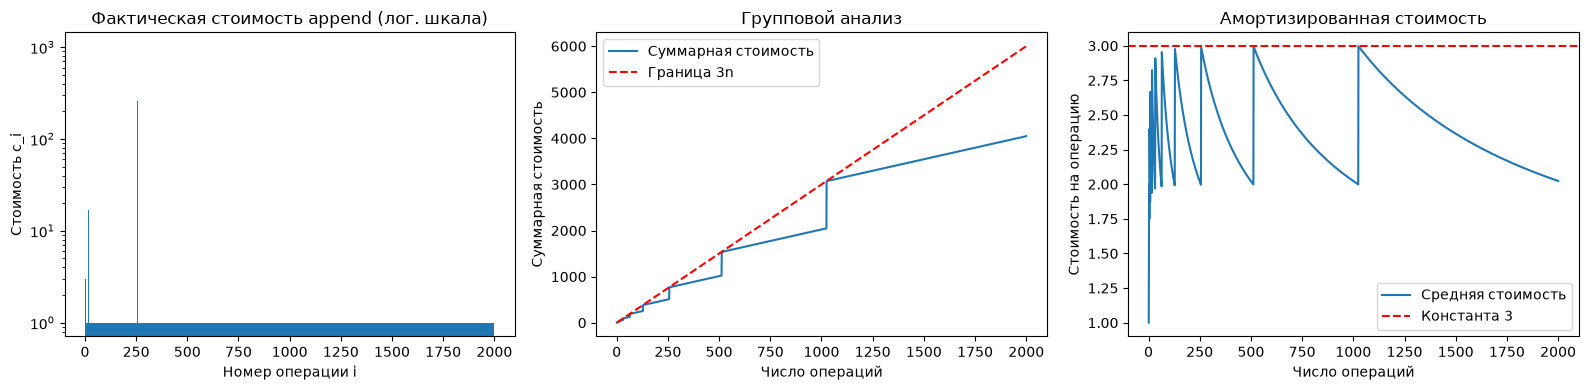

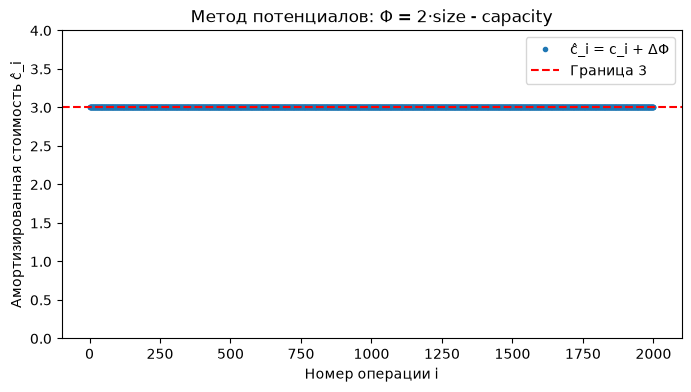

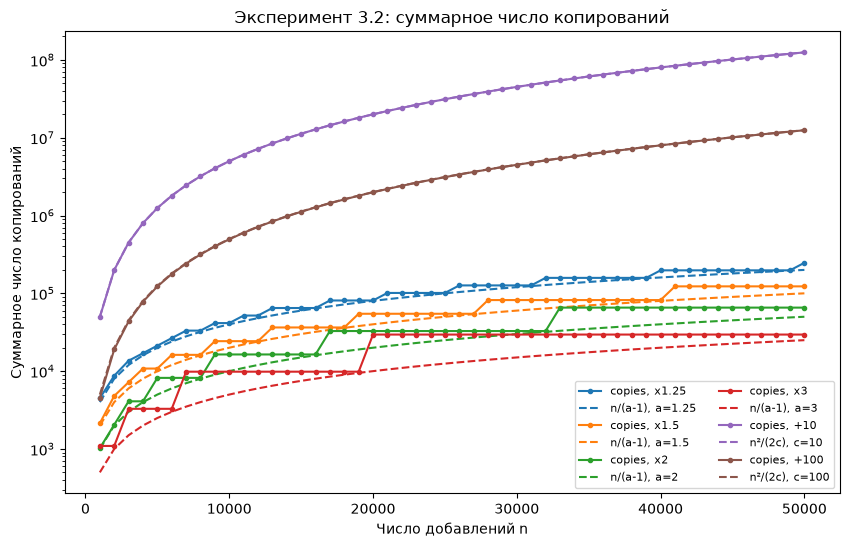

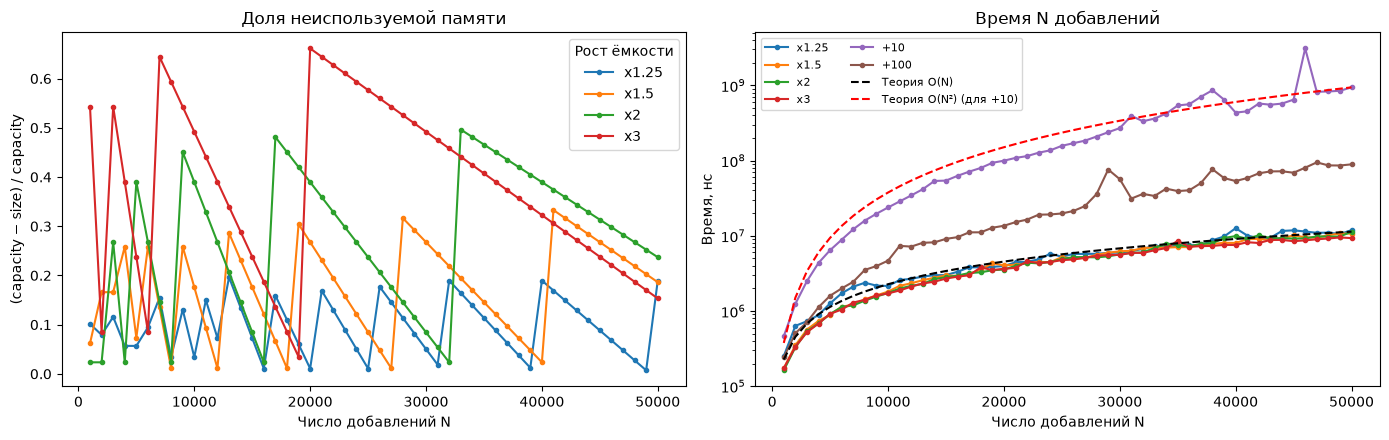

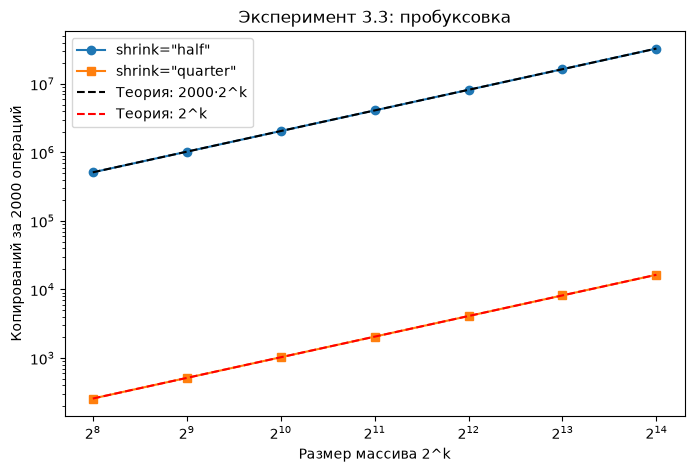

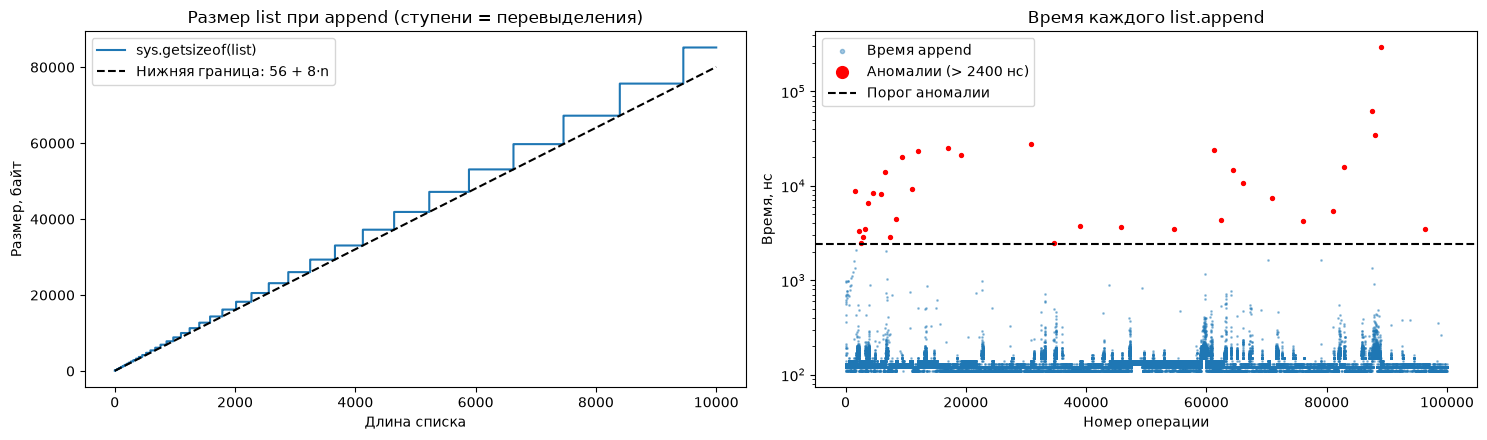

In [18]:
ops31 = np.arange(1, N31 + 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(ops31, costs31, width=1.0)
axes[0].set_yscale("log")
axes[0].set_xlabel("Номер операции i")
axes[0].set_ylabel("Стоимость c_i")
axes[0].set_title("Фактическая стоимость append (лог. шкала)")

axes[1].plot(ops31, cum31, label="Суммарная стоимость")
axes[1].plot(ops31, 3 * ops31, "r--", label="Граница 3n")
axes[1].set_xlabel("Число операций")
axes[1].set_ylabel("Суммарная стоимость")
axes[1].set_title("Групповой анализ")
axes[1].legend()

axes[2].plot(ops31, np.array(cum31) / ops31, label="Средняя стоимость")
axes[2].axhline(3, color="r", linestyle="--", label="Константа 3")
axes[2].set_xlabel("Число операций")
axes[2].set_ylabel("Стоимость на операцию")
axes[2].set_title("Амортизированная стоимость")
axes[2].legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(ops31, amort31, ".", label="ĉ_i = c_i + ΔΦ")
plt.axhline(3, color="r", linestyle="--", label="Граница 3")
plt.xlabel("Номер операции i")
plt.ylabel("Амортизированная стоимость ĉ_i")
plt.title("Метод потенциалов: Φ = 2·size - capacity")
plt.ylim(0, 4)
plt.legend()
plt.show()

# 3.2: суммарное число копирований + теория
colors = dict(zip(STRATEGIES, plt.rcParams["axes.prop_cycle"].by_key()["color"]))
plt.figure(figsize=(10, 6))
for name, kw in STRATEGIES.items():
    plt.plot(
        N_GRID32,
        copies32[name],
        color=colors[name],
        marker="o",
        ms=3,
        label=f"copies, {name}",
    )
    if "growth" in kw:
        th = [N / (kw["growth"] - 1) for N in N_GRID32]
        lab = f"n/(a-1), a={kw['growth']}"
    else:
        th = [N * N / (2 * kw["additive"]) for N in N_GRID32]
        lab = f"n²/(2c), c={kw['additive']}"
    plt.plot(N_GRID32, th, color=colors[name], linestyle="--", label=lab)
plt.yscale("log")
plt.xlabel("Число добавлений n")
plt.ylabel("Суммарное число копирований")
plt.title("Эксперимент 3.2: суммарное число копирований")
plt.legend(ncol=2, fontsize=8)
plt.show()

# 3.2: доля неиспользуемой памяти и время
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name in ["x1.25", "x1.5", "x2", "x3"]:
    axes[0].plot(N_GRID32, waste32[name], marker="o", ms=3, label=name)
axes[0].set_xlabel("Число добавлений N")
axes[0].set_ylabel("(capacity − size) / capacity")
axes[0].set_title("Доля неиспользуемой памяти")
axes[0].legend(title="Рост ёмкости")
for name in STRATEGIES:
    axes[1].plot(
        N_GRID32, time32[name], color=colors[name], marker="o", ms=3, label=name
    )
axes[1].plot(N_GRID32, theory(N_GRID32, time32["x2"], 1), "k--", label="Теория O(N)")
axes[1].plot(
    N_GRID32, theory(N_GRID32, time32["+10"], 2), "r--", label="Теория O(N²) (для +10)"
)
axes[1].set_yscale("log")
axes[1].set_xlabel("Число добавлений N")
axes[1].set_ylabel("Время, нс")
axes[1].set_title("Время N добавлений")
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

# 3.3
plt.figure(figsize=(8, 5))
xs = [2 ** k for k in K_RANGE]
plt.plot(xs, thrash["half"], marker="o", label='shrink="half"')
plt.plot(xs, thrash["quarter"], marker="s", label='shrink="quarter"')
plt.plot(xs, [2000 * x for x in xs], "k--", label="Теория: 2000·2^k")
plt.plot(xs, xs, "r--", label="Теория: 2^k")
plt.xscale("log", base=2)
plt.yscale("log")
plt.xlabel("Размер массива 2^k")
plt.ylabel("Копирований за 2000 операций")
plt.title("Эксперимент 3.3: пробуксовка")
plt.legend()
plt.show()

# 3.4
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
lens34 = np.arange(1, 10_001)
axes[0].step(lens34, sizes34, where="post", label="sys.getsizeof(list)")
axes[0].plot(lens34, base + 8 * lens34, "k--", label="Нижняя граница: 56 + 8·n")
axes[0].set_xlabel("Длина списка")
axes[0].set_ylabel("Размер, байт")
axes[0].set_title("Размер list при append (ступени = перевыделения)")
axes[0].legend()

idx = np.arange(M34)
axes[1].scatter(idx, append_ns, s=1, alpha=0.4, label="Время append")
axes[1].scatter(
    anomal, append_ns[anomal], s=8, color="red", label=f"Аномалии (> {THRESH:.0f} нс)"
)
axes[1].axhline(THRESH, color="k", linestyle="--", label="Порог аномалии")
axes[1].set_yscale("log")
axes[1].set_xlabel("Номер операции")
axes[1].set_ylabel("Время, нс")
axes[1].set_title("Время каждого list.append")
axes[1].legend(markerscale=3)
plt.tight_layout()
plt.show()

### Анализ результатов + ответы на вопросы

1. Сравните теоретическую асимптотику с экспериментальными данными. Совпадает ли форма кривых?
2. Чем отличается амортизированная оценка от оценки среднего случая из прошлой лабораторной?
3. Какой коэффициент роста вы бы выбрали и почему? Опишите компромисс между временем и памятью.
4. Какой коэффициент роста у `list` в вашей версии Python? Совпадают ли «скачки» времени `append` с моментами перевыделения памяти? Почему совпадение неидеальное?
5. Объясните пробуксовку на результатах эксперимента 3.3.
6. Почему динамический массив с амортизированным $O(1)$ может не подойти для системы реального времени (например, управления двигателем)?

Ответы (задание 3)

1. Опыт 3.1: максимум одной операции 1025, сумма 4047 при n = 2000, это меньше 3n = 6000, среднее около 2.02, амортизированная стоимость не больше 3 для всех i (проверено assert). Опыт 3.2, копирований при N = 50000: x2 65 535, x3 29 524, x1.5 122 904, x1.25 246 853. Растут линейно по n и как 1/(a-1) при уменьшении a; теоретическая кривая n/(a-1) это верхняя граница. Для +10 и +100: 124 980 000 и 12 475 500, как n^2/(2c) = 125·10^6 и 12.5·10^6. Время +10 около 1160 мс против 15 мс у x2.

2. Средний случай усредняет по распределению входов, и неудачный вход его ломает. Амортизированная оценка это гарантия для любой последовательности: n операций стоят не больше n·c. Одна операция при этом может стоить O(n) (в 3.1 это 1025).

3. Брать 1.5–2. Копирований мало (x2 около n, x1.5 около 2.5n), пустой памяти в среднем 18–27%. x3 копирует меньше (0.6n), но держит 38% пустой памяти. x1.25 тратит 10% памяти, но копирует в 4 раза больше, чем x2. CPython взял около 1.125 ради экономии памяти. Прибавка константы не годится: O(n) на операцию.

4. Отношение соседних ёмкостей около 1.125, формула CPython new = n + n/8 + 6, округление вниз до кратного 4. Из 100 000 append было 66 перевыделений, медленных (больше 20 медиан, около 3.6 мкс) только 22, и лишь 4 из них совпали с перевыделением. Причины: realloc часто расширяет блок на месте без копирования, а часть выбросов дают сборщик мусора, планировщик ОС, кэш-промахи и сам таймер.

5. При half после сжатия массив заполнен доверху: следующий append его расширяет, следующий pop снова сжимает. Каждая из 2000 операций копирует 2^k элементов, всего 2000·2^k (8.2·10^6 при k = 12, 3.3·10^7 при k = 14). При quarter копирований всего 2^k, один раз на первом расширении. Между порогами роста и сжатия нужен зазор в O(capacity) операций.

6. Амортизация ограничивает сумму, а не одну операцию. append с перевыделением стоит O(n) (в 3.1 это 1025 против 1), и контроллер двигателя пропустит дедлайн. Нужны структуры с O(1) в худшем случае: заранее выделенный или кольцевой буфер, копирование по частям.

# Задание 4 (3 балла). Очередь на двух стеках

Очередь реализуется на двух стеках `in_stack` и `out_stack`:
* `enqueue(x)` — `push` в `in_stack`;
* `dequeue()` — если `out_stack` пуст, **все** элементы перекладываются из `in_stack` в `out_stack`; затем `pop` из `out_stack`.

Каждый элемент перекладывается не более одного раза, поэтому амортизированная стоимость всех операций — $O(1)$. Потенциал: $\Phi = 2\cdot|\text{in\_stack}|$.

Если хранить в стеках пары (значение, минимум ниже), то получится **очередь с минимумом**, с помощью которой задача о минимуме в скользящем окне решается за $O(n)$.

### Предварительная подготовка

1. Реализовать класс `TwoStackQueue` на двух стеках (можно использовать `ArrayStack` из задания 2 или `list` с операциями только на конце). Методы: `enqueue`, `dequeue`, `peek`, `is_empty`, `__len__`. Счётчики: `self.stack_ops` — общее число операций `push`/`pop` над внутренними стеками, `self.last_cost` — число таких операций в последнем вызове.
2. Реализовать классы `MinStack` (`push`, `pop`, `get_min`, `__len__`) и `MinQueue` (`enqueue`, `dequeue`, `get_min`, `__len__`), где все операции работают за амортизированное $O(1)$.
3. Реализовать `sliding_window_min(arr, k)` с помощью `MinQueue` и наивную версию `sliding_window_min_naive(arr, k)` за $O(nk)$.
4. Доказать **тремя методами**, что амортизированная стоимость операций `TwoStackQueue` — $O(1)$. Указать худший случай для одной операции.

In [19]:
class TwoStackQueue:
    def __init__(self):
        self.in_stack = []
        self.out_stack = []
        self.stack_ops = 0
        self.last_cost = 0

    def _push(self, st, x):
        st.append(x)
        self.stack_ops += 1
        self.last_cost += 1

    def _pop(self, st):
        self.stack_ops += 1
        self.last_cost += 1
        return st.pop()

    def _fill_out(self):
        """Перекладываем ВСЕ элементы, только когда out_stack пуст."""
        # каждый элемент перекладывается максимум один раз, поэтому в сумме это O(1) на элемент
        if not self.out_stack:
            while self.in_stack:
                self._push(self.out_stack, self._pop(self.in_stack))

    def enqueue(self, x):
        self.last_cost = 0
        self._push(self.in_stack, x)

    def dequeue(self):
        self.last_cost = 0
        self._fill_out()
        if not self.out_stack:
            raise IndexError("dequeue from empty queue")
        return self._pop(self.out_stack)

    def peek(self):
        self.last_cost = 0
        self._fill_out()
        if not self.out_stack:
            raise IndexError("peek from empty queue")
        return self.out_stack[-1]

    def is_empty(self):
        return not self.in_stack and not self.out_stack

    def __len__(self):
        return len(self.in_stack) + len(self.out_stack)

class MinStack:
    def __init__(self):
        self._data = []  # пары (значение, минимум среди элементов не выше)

    def push(self, x):
        m = x if not self._data else min(x, self._data[-1][1])
        self._data.append((x, m))

    def pop(self):
        if not self._data:
            raise IndexError("pop from empty stack")
        return self._data.pop()[0]

    def get_min(self):
        if not self._data:
            raise IndexError("get_min from empty stack")
        return self._data[-1][1]

    def __len__(self):
        return len(self._data)

class MinQueue:
    def __init__(self):
        self.in_stack = MinStack()
        self.out_stack = MinStack()

    def enqueue(self, x):
        self.in_stack.push(x)

    def dequeue(self):
        if len(self.out_stack) == 0:
            while len(self.in_stack) > 0:
                self.out_stack.push(self.in_stack.pop())
        if len(self.out_stack) == 0:
            raise IndexError("dequeue from empty queue")
        return self.out_stack.pop()

    def get_min(self):
        if len(self) == 0:
            raise IndexError("get_min from empty queue")
        if len(self.in_stack) == 0:
            return self.out_stack.get_min()
        if len(self.out_stack) == 0:
            return self.in_stack.get_min()
        return min(self.in_stack.get_min(), self.out_stack.get_min())

    def __len__(self):
        return len(self.in_stack) + len(self.out_stack)

def sliding_window_min(arr, k):
    q = MinQueue()
    res = []
    for i, x in enumerate(arr):
        q.enqueue(x)
        if i >= k:
            q.dequeue()
        if i >= k - 1:
            res.append(q.get_min())
    return res

def sliding_window_min_naive(arr, k):
    return [min(arr[i : i + k]) for i in range(len(arr) - k + 1)]

### Доказательства

Каждый `enqueue` — 1 операция стека (`push` в `in_stack`). Каждый `dequeue` — 1 `pop` из `out_stack` плюс, если `out_stack` пуст, перекладка: для каждого из $m$ элементов `in_stack` по одному `pop` и одному `push`, то есть $2m$ операций.

**Групповой метод.** Каждый элемент проходит не более четырёх операций: `push` в `in_stack`, `pop` из `in_stack`, `push` в `out_stack`, `pop` из `out_stack`. Это потому что перекладка происходит только при пустом `out_stack`, и перекладывается весь `in_stack`: элемент из `out_stack` обратно не возвращается и второй раз в `in_stack` не попадает. Поэтому $n$ операций, среди которых $e$ вызовов `enqueue`, стоят не более $4e \le 4n$; средняя стоимость $\le 4 = O(1)$.

**Бухгалтерский метод.** За `enqueue` берём 3 монеты, за `dequeue` — 1. При `enqueue` 1 монета оплачивает `push` в `in_stack`, ещё 2 кладём на элемент (для будущих `pop` из `in_stack` и `push` в `out_stack`). При перекладке эти монеты оплачивают все $2m$ операций. Единственная монета `dequeue` оплачивает финальный `pop` из `out_stack`. Баланс никогда не отрицателен ⇒ амортизированная стоимость $O(1)$.

**Метод потенциалов.** $\Phi = 2\cdot|\text{in\_stack}| \ge 0$, $\Phi_0 = 0$.
* `enqueue`: $c = 1$, $\Delta\Phi = +2$ ⇒ $\hat c = 3$.
* `dequeue` без перекладки: $c = 1$, $\Delta\Phi = 0$ ⇒ $\hat c = 1$.
* `dequeue` с перекладкой $m$ элементов: $c = 2m + 1$, $\Delta\Phi = -2m$ ⇒ $\hat c = 1$.

Все $\hat c_i \le 3$ ⇒ $O(1)$ амортизированно.

**Худший случай одной операции:** `dequeue` сразу после $n$ вызовов `enqueue` — $2n+1$ операций стека, то есть $\Theta(n)$. Именно поэтому оценка только амортизированная, а не в худшем случае.

In [20]:
from collections import deque

q = TwoStackQueue()
for x in [1, 2, 3]:
    q.enqueue(x)
assert (
    q.dequeue() == 1 and q.last_cost == 3 + 3 + 1
)  # 3 pop + 3 push при перекладке + 1 pop
q.enqueue(4)
assert [q.dequeue(), q.dequeue()] == [2, 3] and q.last_cost == 1
assert q.peek() == 4 and len(q) == 1
assert q.dequeue() == 4 and q.is_empty()
try:
    q.dequeue()
    assert False
except IndexError:
    pass

# случайный тест против deque
random.seed(0)
q, ref = TwoStackQueue(), deque()
for _ in range(10000):
    if ref and random.random() < 0.45:
        assert q.dequeue() == ref.popleft()
    else:
        x = random.randint(-100, 100)
        q.enqueue(x)
        ref.append(x)
    assert len(q) == len(ref)

ms = MinStack()
for x in [5, 3, 7, 3, 1]:
    ms.push(x)
assert ms.get_min() == 1
ms.pop()
assert ms.get_min() == 3
ms.pop()
assert ms.get_min() == 3
ms.pop()
ms.pop()
assert ms.get_min() == 5

mq = MinQueue()
for x in [4, 2, 12, 3]:
    mq.enqueue(x)
assert mq.get_min() == 2
mq.dequeue()
assert mq.get_min() == 2
mq.dequeue()
assert mq.get_min() == 3

assert sliding_window_min([4, 2, 12, 3, 8, 1, 7], 3) == [2, 2, 3, 1, 1]
arr = [random.randint(0, 1000) for _ in range(500)]
for k in (1, 5, 50, 500):
    assert sliding_window_min(arr, k) == sliding_window_min_naive(arr, k)
print("Все проверки пройдены!")

Все проверки пройдены!


### Провести эксперименты

**Эксперимент 4.1. Стоимость отдельных операций.** Для каждого из трёх сценариев записать `last_cost` каждой операции, суммарную и среднюю стоимость, а также $\hat{c}_i = c_i + \Delta\Phi$:
* сценарий A: 1000 `enqueue`, затем 1000 `dequeue`;
* сценарий B: 100 блоков «10 `enqueue`, 10 `dequeue`»;
* сценарий C: 2000 случайных операций (`enqueue` с вероятностью 0.6, иначе `dequeue`, если очередь не пуста).

**Эксперимент 4.2. Сравнение очередей.** Для N от 5000 до 50000 с шагом 5000 измерить среднее время серии «N `enqueue`, затем N `dequeue`» и серии «N раз: `enqueue`, `dequeue`» для `TwoStackQueue`, `LinkedQueue`, `NaiveListQueue` (из задания 2) и `deque`.

**Эксперимент 4.3. Когда амортизация ломается.** Создать `TwoStackQueue` из N элементов (только `enqueue`). Сохранить её копию (`copy.deepcopy`) и 100 раз выполнить `dequeue` **на свежей копии того же состояния**. Подсчитать суммарную стоимость этих 100 операций для N от 1000 до 10000 и сравнить с 100 последовательными `dequeue` на одной очереди.

**Эксперимент 4.4. Скользящее окно.** Для массива из 20 000 случайных чисел и $k$ ∈ {10, 50, 100, 500, 1000, 2000} измерить время `sliding_window_min` и `sliding_window_min_naive`.

In [21]:
# ---------- Эксперимент 4.1 ----------
def run_scenario(ops):
    q = TwoStackQueue()
    costs, amorts, cum = [], [], []
    phi_prev, total = 0, 0
    for op in ops:
        if op == "e":
            q.enqueue(0)
        else:
            q.dequeue()
        phi = 2 * len(q.in_stack)
        costs.append(q.last_cost)
        amorts.append(q.last_cost + phi - phi_prev)
        phi_prev = phi
        total += q.last_cost
        cum.append(total)
    return costs, amorts, cum

random.seed(42)
ops_C, size = [], 0
for _ in range(2000):
    if size == 0 or random.random() < 0.6:
        ops_C.append("e")
        size += 1
    else:
        ops_C.append("d")
        size -= 1

SCENARIOS = {
    "A: 1000 enq, затем 1000 deq": ["e"] * 1000 + ["d"] * 1000,
    "B: 100 x (10 enq, 10 deq)": (["e"] * 10 + ["d"] * 10) * 100,
    "C: 2000 случайных (p_enq = 0.6)": ops_C,
}
scen = {}
for name, ops in SCENARIOS.items():
    costs, amorts, cum = run_scenario(ops)
    scen[name] = dict(ops=ops, costs=costs, amorts=amorts, cum=cum, enq=ops.count("e"))
    assert max(amorts) <= 3 and cum[-1] <= 4 * ops.count("e")
    print(
        f"{name:34s} max c_i = {max(costs):5d}, сумма = {cum[-1]:5d}, средняя = {cum[-1] / len(ops):.3f}, "
        f"max ĉ = {max(amorts)}, 4·enq = {4 * ops.count('e')}"
    )

# ---------- Эксперимент 4.2 ----------
SIZES4 = list(range(5000, 50001, 5000))

def seq_series(Q):  # N enqueue, затем N dequeue
    def run(N):
        q = Q()
        for i in range(N):
            q.enqueue(i)
        for _ in range(N):
            q.dequeue()

    return run

def alt_series(Q):  # N раз: enqueue, dequeue
    def run(N):
        q = Q()
        for i in range(N):
            q.enqueue(i)
            q.dequeue()

    return run

def deque_seq(N):
    q = deque()
    for i in range(N):
        q.append(i)
    for _ in range(N):
        q.popleft()

def deque_alt(N):
    q = deque()
    for i in range(N):
        q.append(i)
        q.popleft()

QCLASSES = {
    "TwoStackQueue": TwoStackQueue,
    "LinkedQueue": LinkedQueue,
    "NaiveListQueue": NaiveListQueue,
}
time_seq = {
    n: [measure_series(seq_series(Q), N, 7) for N in SIZES4]
    for n, Q in QCLASSES.items()
}
time_alt = {
    n: [measure_series(alt_series(Q), N, 7) for N in SIZES4]
    for n, Q in QCLASSES.items()
}
time_seq["deque"] = [measure_series(deque_seq, N, 7) for N in SIZES4]
time_alt["deque"] = [measure_series(deque_alt, N, 7) for N in SIZES4]
for title, d in (
    ("N enqueue + N dequeue", time_seq),
    ("N x (enqueue, dequeue)", time_alt),
):
    print(title, {n: f"{ts[-1] / 1e6:.1f} мс" for n, ts in d.items()})

# ---------- Эксперимент 4.3 ----------
import copy

SIZES43 = list(range(1000, 10001, 1000))
cost_fresh, cost_seq = [], []
for N in SIZES43:
    base_q = TwoStackQueue()
    for i in range(N):
        base_q.enqueue(i)
    total = 0
    for _ in range(100):
        fresh = copy.deepcopy(
            base_q
        )  # каждый раз — свежее состояние «N элементов в in_stack»
        fresh.dequeue()
        total += fresh.last_cost
    cost_fresh.append(total)

    q = copy.deepcopy(base_q)
    total = 0
    for _ in range(100):
        q.dequeue()
        total += q.last_cost
    cost_seq.append(total)
print("N=10000: на свежих копиях", cost_fresh[-1], " последовательно", cost_seq[-1])

# ---------- Эксперимент 4.4 ----------
rng44 = random.Random(7)
arr44 = [rng44.randint(0, 10 ** 6) for _ in range(20_000)]
KS = [10, 50, 100, 500, 1000, 2000]
t_minq, t_naive = [], []
for k in KS:
    assert sliding_window_min(arr44, k) == sliding_window_min_naive(arr44, k)
    t_minq.append(measure_series(lambda _: sliding_window_min(arr44, k), 0, 5))
    t_naive.append(measure_series(lambda _: sliding_window_min_naive(arr44, k), 0, 5))
for k, a, b in zip(KS, t_minq, t_naive):
    print(
        f"k={k:5d}: MinQueue {a / 1e6:8.1f} мс, наивный {b / 1e6:8.1f} мс, отношение {b / a:6.2f}"
    )

A: 1000 enq, затем 1000 deq        max c_i =  2001, сумма =  4000, средняя = 2.000, max ĉ = 3, 4·enq = 4000
B: 100 x (10 enq, 10 deq)          max c_i =    21, сумма =  4000, средняя = 2.000, max ĉ = 3, 4·enq = 4000
C: 2000 случайных (p_enq = 0.6)    max c_i =   619, сумма =  4062, средняя = 2.031, max ĉ = 3, 4·enq = 4720
N enqueue + N dequeue {'TwoStackQueue': '21.8 мс', 'LinkedQueue': '23.1 мс', 'NaiveListQueue': '145.6 мс', 'deque': '3.4 мс'}
N x (enqueue, dequeue) {'TwoStackQueue': '23.9 мс', 'LinkedQueue': '12.1 мс', 'NaiveListQueue': '5.8 мс', 'deque': '2.0 мс'}
N=10000: на свежих копиях 2000100  последовательно 20100
k=   10: MinQueue     24.6 мс, наивный      5.5 мс, отношение   0.23
k=   50: MinQueue     24.7 мс, наивный     13.8 мс, отношение   0.56
k=  100: MinQueue     24.7 мс, наивный     24.1 мс, отношение   0.97
k=  500: MinQueue     26.4 мс, наивный    102.3 мс, отношение   3.87
k= 1000: MinQueue     27.2 мс, наивный    194.8 мс, отношение   7.15
k= 2000: MinQueue     2

### Построить графики

16. Эксперимент 4.1: для каждого сценария — стоимость каждой операции и суммарная стоимость с границей $4 \cdot (\text{число enqueue})$.
17. Эксперимент 4.2: на одном графике — время всех очередей (отдельно для двух серий). Теоретические кривые пунктиром.
18. Эксперимент 4.3: суммарная стоимость 100 `dequeue` в двух режимах в зависимости от N.
19. Эксперимент 4.4: время двух решений в зависимости от $k$.

**Требования к графикам:**

Сделайте
* Подписи осей
* Заголовок
* Легенду с пояснением всех линий
* Теоретические кривые — пунктирной линией

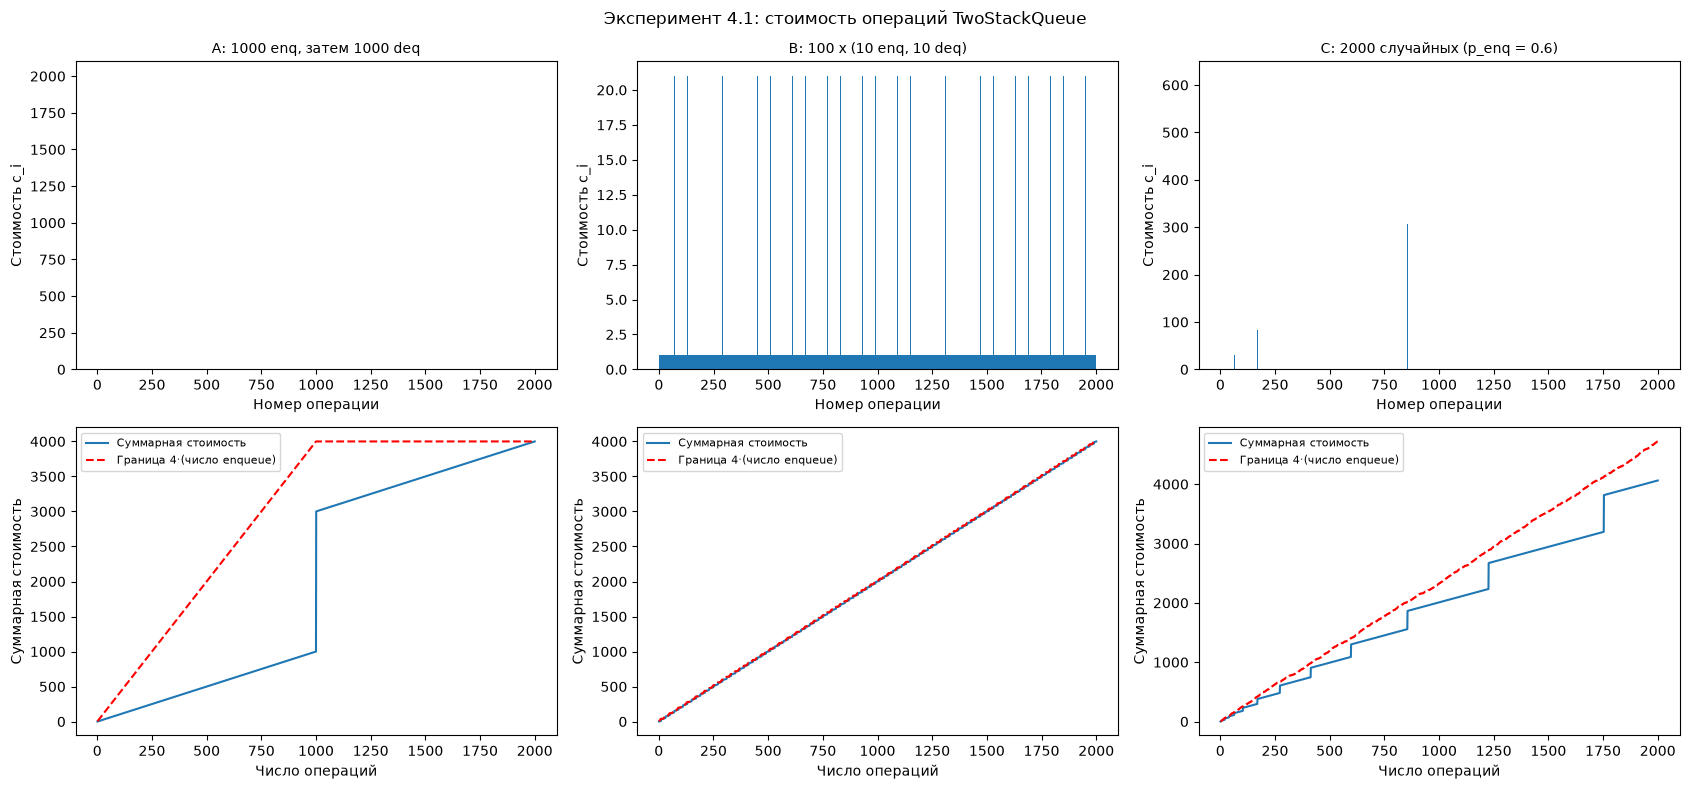

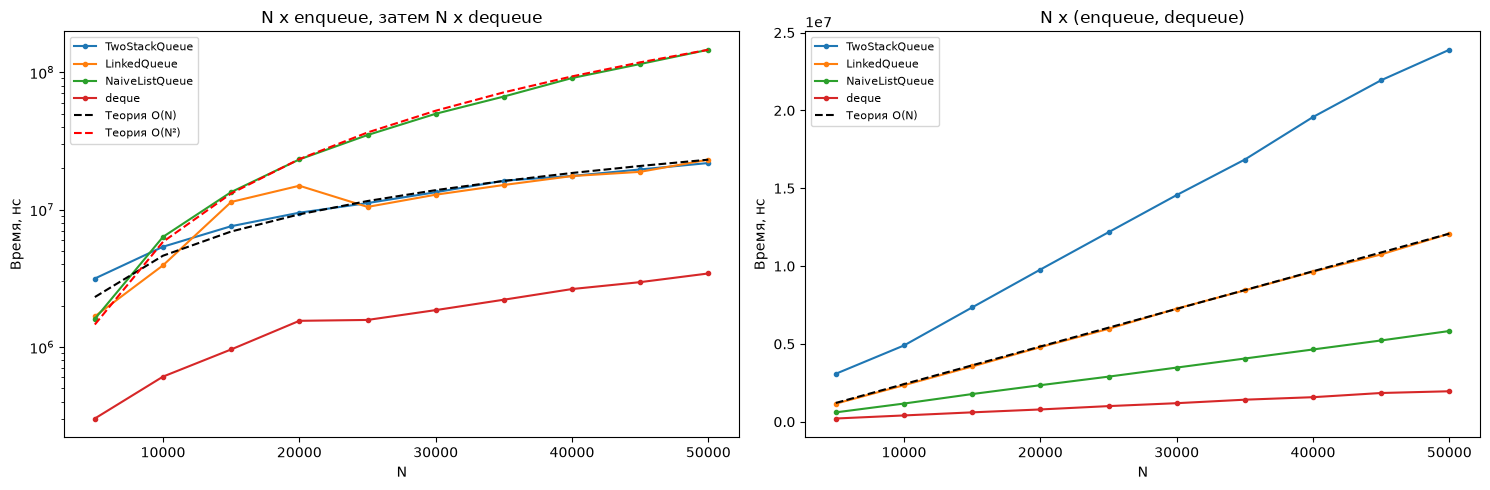

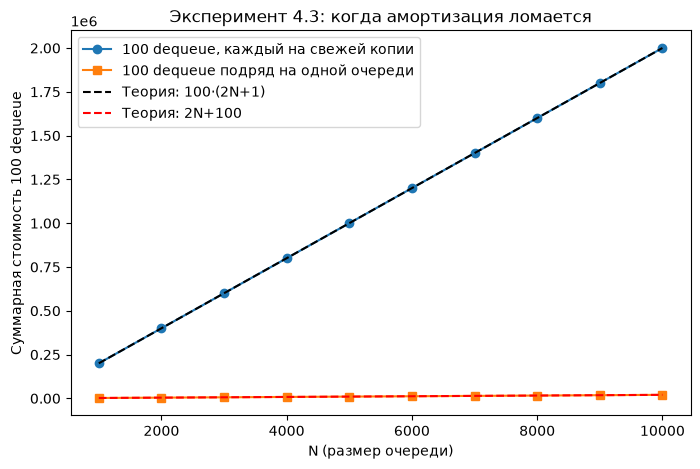

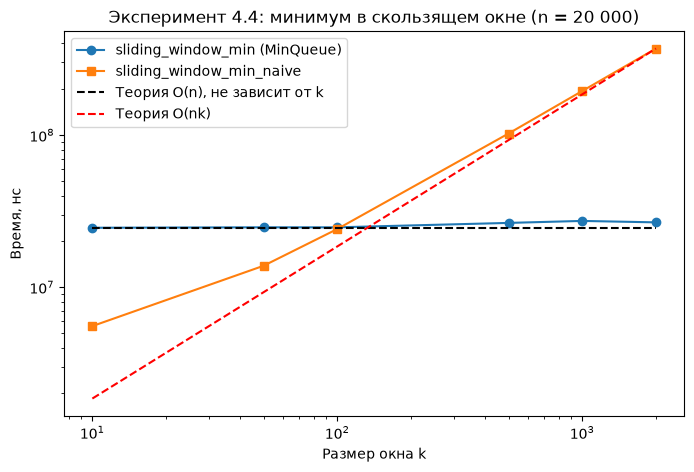

In [22]:
# 4.1
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for j, (name, d) in enumerate(scen.items()):
    n_ops = len(d["costs"])
    xs = np.arange(1, n_ops + 1)
    axes[0, j].bar(xs, d["costs"], width=1.0)
    axes[0, j].set_xlabel("Номер операции")
    axes[0, j].set_ylabel("Стоимость c_i")
    axes[0, j].set_title(name, fontsize=10)
    axes[1, j].plot(xs, d["cum"], label="Суммарная стоимость")
    axes[1, j].plot(
        xs,
        4 * np.cumsum([op == "e" for op in d["ops"]]),
        "r--",
        label="Граница 4·(число enqueue)",
    )
    axes[1, j].set_xlabel("Число операций")
    axes[1, j].set_ylabel("Суммарная стоимость")
    axes[1, j].legend(fontsize=8)
plt.suptitle("Эксперимент 4.1: стоимость операций TwoStackQueue")
plt.tight_layout()
plt.show()

# 4.2
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, d, title in (
    (axes[0], time_seq, "N x enqueue, затем N x dequeue"),
    (axes[1], time_alt, "N x (enqueue, dequeue)"),
):
    for name, ts in d.items():
        ax.plot(SIZES4, ts, marker="o", ms=3, label=name)
    ax.plot(SIZES4, theory(SIZES4, d["LinkedQueue"], 1), "k--", label="Теория O(N)")
    if d is time_seq:
        ax.plot(
            SIZES4, theory(SIZES4, d["NaiveListQueue"], 2), "r--", label="Теория O(N²)"
        )
        ax.set_yscale("log")
    ax.set_xlabel("N")
    ax.set_ylabel("Время, нс")
    ax.set_title(title)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# 4.3
plt.figure(figsize=(8, 5))
plt.plot(SIZES43, cost_fresh, marker="o", label="100 dequeue, каждый на свежей копии")
plt.plot(SIZES43, cost_seq, marker="s", label="100 dequeue подряд на одной очереди")
plt.plot(
    SIZES43, [100 * (2 * N + 1) for N in SIZES43], "k--", label="Теория: 100·(2N+1)"
)
plt.plot(SIZES43, [2 * N + 100 for N in SIZES43], "r--", label="Теория: 2N+100")
plt.xlabel("N (размер очереди)")
plt.ylabel("Суммарная стоимость 100 dequeue")
plt.title("Эксперимент 4.3: когда амортизация ломается")
plt.legend()
plt.show()

# 4.4
plt.figure(figsize=(8, 5))
plt.plot(KS, t_minq, marker="o", label="sliding_window_min (MinQueue)")
plt.plot(KS, t_naive, marker="s", label="sliding_window_min_naive")
plt.plot(KS, [t_minq[0]] * len(KS), "k--", label="Теория O(n), не зависит от k")
plt.plot(KS, theory(KS, t_naive, 1), "r--", label="Теория O(nk)")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Размер окна k")
plt.ylabel("Время, нс")
plt.title("Эксперимент 4.4: минимум в скользящем окне (n = 20 000)")
plt.legend()
plt.show()

### Анализ результатов + ответы на вопросы

1. Сравните теоретическую асимптотику с экспериментальными данными. Совпадает ли форма кривых?
2. В каком сценарии эксперимента 4.1 максимальная стоимость одной операции наибольшая? Почему при этом средняя стоимость во всех сценариях ограничена константой?
3. Почему `TwoStackQueue` медленнее `deque`, хотя асимптотика одинаковая?
4. Объясните результат эксперимента 4.3. Почему амортизированная оценка перестаёт работать, если «откатывать» состояние структуры?
5. Почему перекладывать элементы можно только при пустом `out_stack`? Что сломается, если перекладывать при каждом `dequeue`?
6. Начиная с какого $k$ решение через `MinQueue` выигрывает у наивного?

Ответы (задание 4)

1. Совпадает. В 4.1 суммарная стоимость везде под 4·(число enqueue), амортизированная стоимость не больше 3. В 4.2 TwoStackQueue, LinkedQueue и deque линейны, NaiveListQueue в серии N+N квадратична, в серии enqueue, dequeue линейна (очередь всегда короткая). В 4.3 стоимость на свежих копиях линейна по N на каждую операцию. В 4.4 MinQueue не зависит от k, наивный растёт линейно по k.

2. Больше всего в сценарии A: 2001 = 2·1000 + 1, один dequeue перекладывает всю очередь. В C 619, в B 21. Средняя везде около 2 (4000 на 2000 операций в A и B, 4062 в C): элемент участвует максимум в 4 операциях стека, дорогая перекладка оплачена дешёвыми enqueue.

3. deque написан на C, append и popleft это один вызов. TwoStackQueue на Python: каждый элемент проходит четыре операции стека через _push и _pop со счётчиками. При N = 50000 около 35 мс против 5 мс. Асимптотика та же, константа другая.

4. На свежих копиях каждый из 100 dequeue перекладывает все N элементов: 100·(2N+1) = 2 000 100 при N = 10000. Подряд на одной очереди перекладка одна: 2N+100 = 20 100, в 100 раз меньше. Амортизация работает для последовательности над одним состоянием: дорогая операция оплачена предыдущими дешёвыми и потенциал после неё обнуляется. Откат возвращает накопленный потенциал, и один и тот же долг можно тратить много раз. С персистентными структурами то же самое.

5. В out_stack порядок выдачи самых старых элементов. Новые поверх непустого out_stack окажутся ближе к выходу, чем старые, и FIFO сломается. Если перекладывать при каждом dequeue, элементы будут ходить туда-обратно, и каждая операция станет O(n) (например, enqueue и dequeue по очереди на длинной очереди).

6. При n = 20000: k = 10 наивный быстрее в 4.5 раза, k = 50 в 1.8 раза, k = 100 почти поровну (около 39 мс), k = 500 MinQueue быстрее в 3 раза, k = 2000 в 14 раз. Выигрыш начинается примерно с k = 100. На малых k встроенный min по короткому срезу работает на C и дешевле двух стеков на Python.

# Задание 5 (2 балла). Двоичная куча

**Двоичная куча (min-heap)** — почти полное двоичное дерево, хранящееся в массиве: у элемента с индексом $i$ дети имеют индексы $2i+1$ и $2i+2$, родитель — $\lfloor (i-1)/2 \rfloor$. Значение в каждом узле не больше значений в детях, поэтому минимум всегда в `heap[0]`.

* `push` — добавить в конец и **просеять вверх** (`sift_up`): $O(\log n)$.
* `pop` — переставить последний элемент в корень и **просеять вниз** (`sift_down`): $O(\log n)$.
* `heapify` — построить кучу из массива, вызывая `sift_down` от середины к началу: $O(n)$.

### Предварительная подготовка

1. Реализовать класс `MinHeap` с методами `push`, `pop`, `peek`, `__len__` и методом класса `MinHeap.heapify(arr)` (построение за $O(n)$). Добавить счётчик сравнений `self.comparisons`.
2. Реализовать `heap_sort(arr)` с помощью вашей кучи.
3. Реализовать `top_k(arr, k)` — $k$ наибольших элементов массива за $O(n \log k)$ с использованием кучи размера $k$.
4. Доказать, что `heapify` работает за $O(n)$, а построение через $n$ вызовов `push` — за $O(n \log n)$.

In [23]:
class MinHeap:
    def __init__(self):
        self.data = []
        self.comparisons = 0

    def __len__(self):
        return len(self.data)

    def _less(self, a, b):
        self.comparisons += 1
        return a < b

    def _sift_up(self, i):
        data = self.data
        while i > 0:
            parent = (i - 1) // 2
            if self._less(data[i], data[parent]):
                data[i], data[parent] = data[parent], data[i]
                i = parent
            else:
                break

    def _sift_down(self, i):
        data = self.data
        n = len(data)
        while True:
            left = 2 * i + 1
            if left >= n:
                break
            smallest = left
            if left + 1 < n and self._less(data[left + 1], data[left]):
                smallest = left + 1
            if self._less(data[smallest], data[i]):
                data[i], data[smallest] = data[smallest], data[i]
                i = smallest
            else:
                break

    def push(self, x):
        self.data.append(x)
        self._sift_up(len(self.data) - 1)

    def peek(self):
        if not self.data:
            raise IndexError("peek from empty heap")
        return self.data[0]

    def pop(self):
        if not self.data:
            raise IndexError("pop from empty heap")
        top = self.data[0]
        last = self.data.pop()
        if self.data:
            self.data[0] = last
            self._sift_down(0)
        return top

    @classmethod
    def heapify(cls, arr):
        h = cls()
        h.data = list(arr)
        for i in range(len(h.data) // 2 - 1, -1, -1):
            h._sift_down(i)
        return h

def heap_sort(arr):
    h = MinHeap.heapify(arr)
    return [h.pop() for _ in range(len(h))]

def top_k(arr, k):
    """k наибольших элементов (по убыванию) за O(n log k): min-куча размера k."""
    if k <= 0:
        return []
    h = MinHeap()
    for x in arr:
        if len(h) < k:
            h.push(x)
        elif x > h.peek():
            h.pop()
            h.push(x)
    res = [h.pop() for _ in range(len(h))]
    res.reverse()
    return res

### Доказательства

**`heapify` — $O(n)$.** `sift_down` из вершины высоты $h$ (высота — длина самого длинного пути вниз до листа) делает не более $h$ шагов, на каждом — 2 сравнения. В почти полном двоичном дереве из $n$ вершин на высоте $h$ не более $\lceil n/2^{h+1} \rceil$ вершин. Суммарное число сравнений
$$T(n) \le \sum_{h=1}^{\lfloor \log_2 n \rfloor} \left\lceil \frac{n}{2^{h+1}} \right\rceil \cdot 2h \le n\sum_{h=1}^{\infty}\frac{h}{2^{h}} + 2\sum_{h=1}^{\log_2 n} h = 2n + O(\log^2 n) = O(n),$$
так как $\sum_{h\ge 1} h/2^h = 2$. Нижняя оценка $\Omega(n)$ очевидна (нужно посмотреть каждый элемент), поэтому $\Theta(n)$. Ключевая идея: вершин, у которых `sift_down` дорогой, мало (половина вершин — листья со стоимостью 0, четверть — со стоимостью $\le 1$ и т.д.).

**Построение через $n$ вызовов `push` — $O(n\log n)$.** При вставке в кучу из $i$ элементов `sift_up` поднимает элемент не выше корня: $\le \lfloor \log_2 (i+1)\rfloor$ сравнений, всего $\le \sum_i \log_2 i = \log_2 n! = O(n\log n)$. Оценка достижима: если вставлять элементы **по убыванию** (для min-кучи каждый новый — меньше всех предыдущих), то каждый поднимается до корня, и $\sum_i \lfloor \log_2 (i+1)\rfloor = \Theta(n \log n)$. Значит, оценка точная.

**`top_k` — $O(n\log k)$.** Куча хранит не более $k$ элементов. Для каждого из $n$ элементов — одно сравнение с `peek` ($O(1)$), а замена (`pop` + `push`) стоит $O(\log k)$. Итого $O(n + n\log k) = O(n\log k)$, память $O(k)$.

In [24]:
h = MinHeap()
for x in [5, 3, 8, 1, 9, 2]:
    h.push(x)
assert h.peek() == 1 and len(h) == 6
assert [h.pop() for _ in range(6)] == [1, 2, 3, 5, 8, 9]
try:
    h.pop()
    assert False
except IndexError:
    pass

data = [random.randint(-1000, 1000) for _ in range(2000)]
h2 = MinHeap.heapify(data[:])
assert [h2.pop() for _ in range(len(data))] == sorted(data)
assert heap_sort(data[:]) == sorted(data)
assert sorted(top_k(data, 10)) == sorted(data)[-10:]
print("Все проверки пройдены!")

Все проверки пройдены!


### Провести эксперименты

5. Для N от 10 000 до 200 000 с шагом 10 000 подсчитать число сравнений при построении кучи через `heapify` и через N вызовов `push` (на случайных данных и на данных, отсортированных по убыванию).
6. Сравнить время `heap_sort`, `heapq` (`heapify` + `heappop`) и `sorted`.
7. Сравнить время `top_k(arr, 10)` и `sorted(arr)[-10:]` для N от 100 000 до 1 000 000.

In [25]:
import heapq

# ---------- сравнения при построении ----------
SIZES5 = list(range(10_000, 200_001, 10_000))
rng5 = random.Random(5)

def comps_heapify(arr):
    return MinHeap.heapify(arr).comparisons

def comps_push(arr):
    h = MinHeap()
    for x in arr:
        h.push(x)
    return h.comparisons

comp = {
    k: []
    for k in (
        "heapify, случайные",
        "pushxN, случайные",
        "heapify, по убыванию",
        "pushxN, по убыванию",
    )
}
for N in SIZES5:
    rnd = [rng5.random() for _ in range(N)]
    desc = list(range(N, 0, -1))
    comp["heapify, случайные"].append(comps_heapify(rnd))
    comp["pushxN, случайные"].append(comps_push(rnd))
    comp["heapify, по убыванию"].append(comps_heapify(desc))
    comp["pushxN, по убыванию"].append(comps_push(desc))
for k, v in comp.items():
    print(f"{k:24s} N=200000: {v[-1]:>9d}  ({v[-1] / SIZES5[-1]:.2f} на элемент)")

# ---------- время сортировок ----------
SORT_SIZES = list(range(10_000, 100_001, 10_000))
sort_data = {N: [rng5.random() for _ in range(N)] for N in SORT_SIZES}

def run_heap_sort(N):
    heap_sort(sort_data[N])

def run_heapq(N):
    h = sort_data[N][:]
    heapq.heapify(h)
    return [heapq.heappop(h) for _ in range(N)]

def run_sorted(N):
    sorted(sort_data[N])

sort_times = {
    "heap_sort (наша куча)": [measure_series(run_heap_sort, N, 7) for N in SORT_SIZES],
    "heapq: heapify + heappop": [measure_series(run_heapq, N, 7) for N in SORT_SIZES],
    "sorted": [measure_series(run_sorted, N, 7) for N in SORT_SIZES],
}
assert heap_sort(sort_data[10_000]) == sorted(sort_data[10_000]) == run_heapq(10_000)
for k, v in sort_times.items():
    print(f"{k:28s} N=100000: {v[-1] / 1e6:9.2f} мс")

# ---------- top-k ----------
TOPK_SIZES = list(range(100_000, 1_000_001, 100_000))
topk_data = {N: [rng5.random() for _ in range(N)] for N in TOPK_SIZES}
assert sorted(top_k(topk_data[100_000], 10)) == sorted(topk_data[100_000])[-10:]
topk_times = {
    "top_k (куча, k = 10)": [
        measure_series(lambda N: top_k(topk_data[N], 10), N, 7) for N in TOPK_SIZES
    ],
    "sorted(arr)[-10:]": [
        measure_series(lambda N: sorted(topk_data[N])[-10:], N, 7) for N in TOPK_SIZES
    ],
}
for k, v in topk_times.items():
    print(f"{k:24s} N=1000000: {v[-1] / 1e6:9.2f} мс")

heapify, случайные       N=200000:    376085  (1.88 на элемент)
pushxN, случайные        N=200000:    455550  (2.28 на элемент)
heapify, по убыванию     N=200000:    399976  (2.00 на элемент)
pushxN, по убыванию      N=200000:   3137875  (15.69 на элемент)
heap_sort (наша куча)        N=100000:    923.10 мс
heapq: heapify + heappop     N=100000:     80.32 мс
sorted                       N=100000:     18.33 мс
top_k (куча, k = 10)     N=1000000:    102.25 мс
sorted(arr)[-10:]        N=1000000:    436.38 мс


### Построить графики

8. На одном графике — число сравнений для двух способов построения (два типа данных). Теоретические кривые $O(n)$ и $O(n \log n)$ — пунктиром.
9. На одном графике — время трёх сортировок.
10. На одном графике — время двух способов поиска top-k.

**Требования к графикам:**

Сделайте
* Подписи осей
* Заголовок
* Легенду с пояснением всех линий
* Теоретические кривые — пунктирной линией

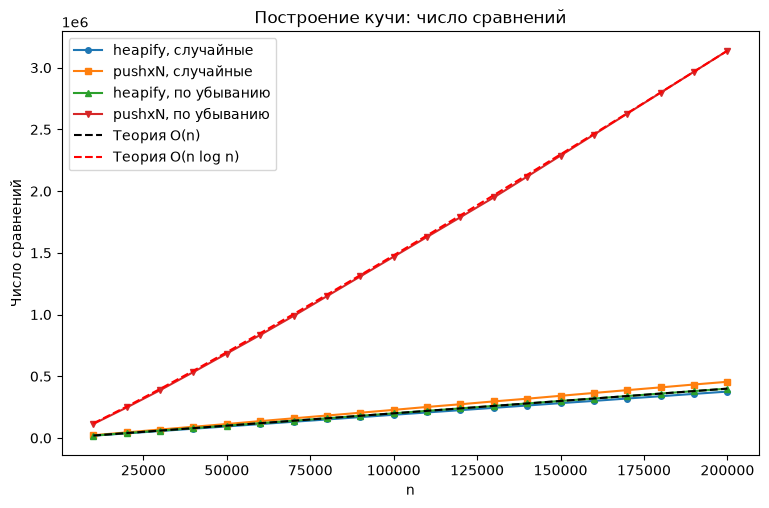

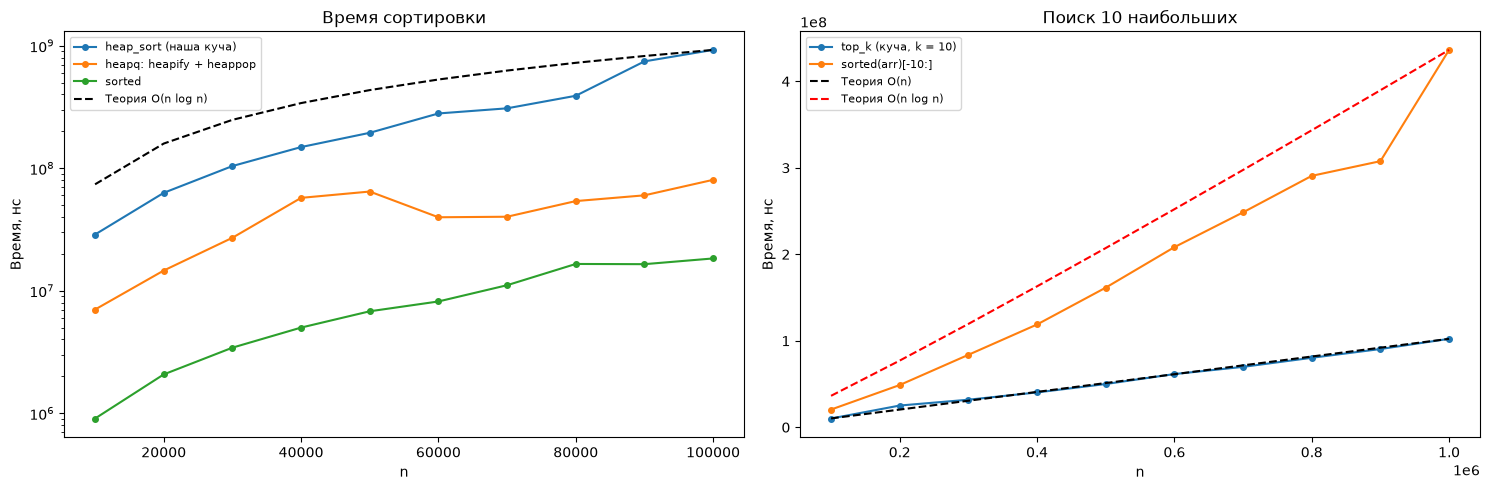

In [26]:
fig, ax = plt.subplots(figsize=(9, 5.5))
styles = {
    "heapify, случайные": "o-",
    "pushxN, случайные": "s-",
    "heapify, по убыванию": "^-",
    "pushxN, по убыванию": "v-",
}
for k, v in comp.items():
    ax.plot(SIZES5, v, styles[k], ms=4, label=k)
ax.plot(
    SIZES5, theory(SIZES5, comp["heapify, по убыванию"], 1), "k--", label="Теория O(n)"
)
nlogn = np.array(SIZES5) * np.log2(SIZES5)
ax.plot(
    SIZES5,
    comp["pushxN, по убыванию"][-1] / nlogn[-1] * nlogn,
    "r--",
    label="Теория O(n log n)",
)
ax.set_xlabel("n")
ax.set_ylabel("Число сравнений")
ax.set_title("Построение кучи: число сравнений")
ax.legend()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for k, v in sort_times.items():
    axes[0].plot(SORT_SIZES, v, marker="o", ms=4, label=k)
nl = np.array(SORT_SIZES) * np.log2(SORT_SIZES)
axes[0].plot(
    SORT_SIZES,
    sort_times["heap_sort (наша куча)"][-1] / nl[-1] * nl,
    "k--",
    label="Теория O(n log n)",
)
axes[0].set_yscale("log")
axes[0].set_xlabel("n")
axes[0].set_ylabel("Время, нс")
axes[0].set_title("Время сортировки")
axes[0].legend(fontsize=8)

for k, v in topk_times.items():
    axes[1].plot(TOPK_SIZES, v, marker="o", ms=4, label=k)
axes[1].plot(
    TOPK_SIZES,
    theory(TOPK_SIZES, topk_times["top_k (куча, k = 10)"], 1),
    "k--",
    label="Теория O(n)",
)
nl = np.array(TOPK_SIZES) * np.log2(TOPK_SIZES)
axes[1].plot(
    TOPK_SIZES,
    topk_times["sorted(arr)[-10:]"][-1] / nl[-1] * nl,
    "r--",
    label="Теория O(n log n)",
)
axes[1].set_xlabel("n")
axes[1].set_ylabel("Время, нс")
axes[1].set_title("Поиск 10 наибольших")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Анализ результатов + ответы на вопросы

1. Сравните теоретическую асимптотику с экспериментальными данными. Совпадает ли форма кривых?
2. Почему `heapify` работает за $O(n)$, хотя вызывает `sift_down` $\frac{n}{2}$ раз, а каждый `sift_down` может стоить $O(\log n)$?
3. На каких данных построение через `push` достигает худшего случая?
4. Почему `heapq` намного быстрее вашей реализации?
5. Для каких задач куча подходит лучше, чем отсортированный массив?

Ответы (задание 5)

1. Совпадает. У heapify число сравнений линейно, около 1.9–2.0 на элемент (200 000 элементов: 376 085 на случайных данных, 399 976 на убывающих, ниже границы 2n). n раз push: на случайных данных около 2.3 сравнения на элемент (sift_up в среднем делает O(1) шагов), на убывающих 3 137 875, это 15.7 на элемент при log2(n) = 17.6, кривая n log n.

2. Стоимость sift_down это не log n, а высота вершины. Половина вершин листья (0 шагов), четверть имеет высоту 1, одна восьмая высоту 2 и так далее. Сумма n/2^(h+1) · h это O(n), потому что сумма h/2^h равна 2. Оценка n/2 · log n завышена: почти все вершины рядом с листьями.

3. Когда каждый новый элемент меньше всех предыдущих, для min-кучи это данные по убыванию. Каждый поднимается до корня, на вставку log i сравнений, всего n log n: 15.7 на элемент против 2.3 на случайных.

4. При n = 10^5 heapq около 83 мс, наша heap_sort около 690 мс, в 8 раз медленнее. heapq написан на C: нет интерпретации байткода на каждый шаг, нет вызова _less и счётчика на каждое сравнение. Асимптотика одна. sorted (Timsort на C, около 24 мс) быстрее обеих.

5. Когда данные меняются: вставка и извлечение минимума по O(log n), а в отсортированном массиве вставка O(n). Приоритетные очереди (Дейкстра, планировщики), top-k в потоке (память O(k), время O(n log k); на 10^6 элементов около 157 мс против 433 мс у полной сортировки), медиана в потоке. Если данные не меняются и нужны произвольные запросы, лучше отсортированный массив (бинарный поиск, диапазоны).

## Выводы

Сделайте общие выводы и заполните таблицу! В каждой ячейке укажите асимптотику в худшем случае / амортизированную и подтвердилась ли она экспериментально.

| Структура \ Операция | Добавление | Удаление | Доступ по индексу / к вершине | Поиск | Память |
|---|---|---|---|---|---|
| **`SinglyLinkedList`** | `push_front`/`push_back` $O(1)$ (подтв.: ops = N) | `pop_front` $O(1)$; `pop_back`, `remove` $O(n)$ | `get(i)` $O(n)$ (подтв.: 173 мкс против 23 нс у `list` при N = 5000) | $O(n)$ | $\Theta(n)$, ≈ 3.1x больше `list` (подтв.) |
| **`ArrayStack`** | `push` $O(1)$ амортиз. (подтв.) | `pop` $O(1)$ (подтв.) | `peek` $O(1)$ | — ($O(n)$) | $\Theta(n)$ |
| **`LinkedStack`** | `push` $O(1)$ (подтв.; ≈ 5x медленнее `ArrayStack`) | `pop` $O(1)$ (подтв.) | `peek` $O(1)$ | — ($O(n)$) | $\Theta(n)$, узел ≈ 48 Б |
| **`LinkedQueue`** | `enqueue` $O(1)$ (подтв.) | `dequeue` $O(1)$ (подтв.) | `peek` $O(1)$ | — ($O(n)$) | $\Theta(n)$ |
| **`NaiveListQueue`** | `enqueue` $O(1)$ амортиз. | `dequeue` $O(n)$, серия $N$ — $\Theta(N^2)$ (подтв.) | `peek` $O(1)$ | — ($O(n)$) | $\Theta(n)$ |
| **`DynamicArray` (x2)** | `append` $O(1)$ амортиз., $\hat c\le3$ (подтв.), худший случай $O(n)$ | `pop` $O(1)$ амортиз. при сжатии на $\frac14$ (подтв.) | $a[i]$ $O(1)$ | $O(n)$ | $\Theta(n)$, до 50 % пустой (в среднем ≈ 27 %) |
| **`DynamicArray` (+c)** | `append` $\Theta(n)$ амортиз., серия $\Theta(n^2/c)$ (подтв.) | то же | $O(1)$ | $O(n)$ | $\Theta(n)$, почти без запаса (подтв.) |
| **`TwoStackQueue`** | `enqueue` $O(1)$ (подтв.) | `dequeue` $O(1)$ амортиз., худший $O(n)$; ломается при откате состояния (подтв. в 4.3) | `peek` $O(1)$ амортиз. | — ($O(n)$) | $\Theta(n)$ |
| **`MinHeap`** | `push` $O(\log n)$ (худший — убывающие данные, подтв.); `heapify` $O(n)$ (подтв.) | `pop` $O(\log n)$ | `peek` $O(1)$ | $O(n)$ | $\Theta(n)$ |

Общие выводы

Реализованы односвязный список (с хвостом и без), стеки, очереди, динамический массив, очередь на двух стеках с минимумом, двоичная куча. Все проверки проходят.

Асимптотика подтвердилась везде, где её можно измерить: линейность O(1)-операций по N, квадрат у NoTail.push_back (12 497 501 операций при N = 5000, около N(N-1)/2), NaiveListQueue и DynamicArray(+c), линейное число копирований при мультипликативном росте, O(n) у heapify против O(n log n) у push на убывающих данных.

Групповой метод, бухгалтерский и потенциалов согласуются: амортизированная стоимость не больше 3 для массива и очереди на двух стеках. Это гарантия на последовательность над одной структурой. Отдельная операция бывает дорогой (1025 в массиве, 2001 в очереди), а при откате состояния оценка ломается (опыт 4.3).

Константы важны не меньше асимптотики. Свои реализации на узлах в 5–160 раз медленнее встроенных (list, deque, heapq, sorted) при той же асимптотике: C, непрерывная память, кэш. Список занимает в 3 раза больше памяти, доступ по индексу в нём в тысячи раз медленнее.

Параметры это компромисс: коэффициент роста массива (время против памяти), порог сжатия (при 1/2 пробуксовка, O(n) на операцию, при 1/4 O(1)), размер окна k (наивный лучше при k до 100, MinQueue при больших).

**Контрольные вопросы**

1. Что такое амортизированная стоимость операции? Чем она отличается от стоимости в худшем и среднем случаях?
2. Сформулируйте групповой метод, метод бухгалтерского учёта и метод потенциалов. Какие условия должна удовлетворять функция потенциала?
3. Почему ёмкость динамического массива нужно умножать, а не увеличивать на константу?
4. Почему сжимать массив нужно при заполнении на четверть, а не наполовину?
5. Почему в очереди на двух стеках каждый элемент перекладывается не более одного раза?
6. Как реализовать стек и очередь так, чтобы все операции работали за $O(1)$ в худшем случае?
7. Чем связный список хуже динамического массива на современных процессорах?

Ответы на контрольные вопросы

1. Верхняя оценка средней стоимости операции на худшей последовательности: сумма c_i / n для любой последовательности из n операций. Худший случай это одна самая дорогая операция. Средний случай это матожидание по распределению входов, то есть вероятностное предположение. Амортизация вероятностей не использует.

2. Групповой: оценить сумму стоимостей n операций и поделить на n. Бухгалтерский: назначить каждой операции плату, излишек лежит монетами на элементах и оплачивает дорогие операции, баланс не уходит в минус. Потенциалов: c_i + Ф_i - Ф_(i-1), где Ф переводит состояние в число, и нужно Ф_i >= Ф_0 для всех i (обычно Ф_0 = 0, Ф >= 0), тогда сумма c_i <= сумма амортизированных.

3. При росте на константу c перевыделения идут каждые c добавлений и копируют всё больше: в сумме около n^2/(2c), то есть O(n) на операцию. При умножении на a > 1 размеры копирований образуют геометрическую прогрессию с суммой O(n/(a-1)).

4. При сжатии на половине в 2 раза массив после сжатия полон, append сразу расширяет, pop снова сжимает: пробуксовка, O(n) на операцию (опыт 3.3). При четверти после сжатия остаётся запас в O(n) операций в обе стороны, он оплачивает копирование.

5. Перекладка идёт только при пустом out_stack и переносит весь in_stack целиком. Назад ничего не возвращается, в in_stack попадают только новые элементы. Значит, у каждого элемента ровно один push и один pop в каждом стеке.

6. Стек на односвязном списке (вставка и удаление в голове): O(1) в худшем случае. Очередь: список с head и tail или кольцевой буфер фиксированной ёмкости. Очередь на двух стеках O(1) только амортизированно; для худшего случая перекладку делают по частям, по несколько элементов за операцию.

7. Узлы списка разбросаны по памяти: нет локальности, каждый переход может быть кэш-промахом, предвыборка не работает, плюс накладные расходы на указатели и аллокации. Массив лежит подряд, обходится быстро и векторизуется, поэтому на практике он быстрее, даже где у списка лучше асимптотика.